In [3]:
!pip install -q \
    pandas==2.2.3 \
    requests==2.32.4 \
    numpy==2.2.6 \
    gradio \
    langchain \
    langchain-openai \
    langchain-core \
    python-dotenv \
    pydantic \
    matplotlib \
    seaborn

print("Package installation completed!")

Package installation completed!


In [4]:
import pandas as pd
import numpy as np
import requests
import gradio as gr
import langchain

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Requests:", requests.__version__)
print("Gradio:", gr.__version__)
print("LangChain:", langchain.__version__)

print("\nAll packages imported successfully!")


Pandas: 2.2.3
NumPy: 2.4.6
Requests: 2.32.4
Gradio: 6.31.0
LangChain: 1.4.8

All packages imported successfully!


In [5]:
import os
import json
import sqlite3
import requests
import pandas as pd
import numpy as np
import gradio as gr

from datetime import datetime, date
from pathlib import Path
from getpass import getpass

from langchain.tools import tool
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:
# STEP 3: UPLOAD JSON DATASETS

from google.colab import files

print("Please upload flights.json, hotels.json and places.json")

uploaded = files.upload()

print("\nUploaded files:")

for filename in uploaded.keys():
    print("✔", filename)


Please upload flights.json, hotels.json and places.json


Saving flights.json to flights.json
Saving hotels.json to hotels.json
Saving places.json to places.json

Uploaded files:
✔ flights.json
✔ hotels.json
✔ places.json


In [7]:
# STEP 4: LOAD AND VALIDATE JSON DATA

DATA_DIR = Path("/content")

def load_json_file(filename):
    file_path = DATA_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"{filename} not found. Please upload the file."
        )

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    if isinstance(data, dict):
        data = data.get("data", data.get("records", data))

    if not isinstance(data, list):
        raise ValueError(f"{filename} must contain a JSON list.")

    return pd.DataFrame(data)


# Load all three datasets
flights_df = load_json_file("flights.json")
hotels_df = load_json_file("hotels.json")
places_df = load_json_file("places.json")


# Check required columns
required_columns = {
    "flights": [
        "flight_id", "airline", "from", "to",
        "departure_time", "arrival_time", "price"
    ],
    "hotels": [
        "hotel_id", "name", "city", "stars",
        "price_per_night", "amenities"
    ],
    "places": [
        "place_id", "name", "city", "type", "rating"
    ]
}

datasets = {
    "flights": flights_df,
    "hotels": hotels_df,
    "places": places_df
}

for name, df in datasets.items():
    missing = set(required_columns[name]) - set(df.columns)

    if missing:
        raise ValueError(
            f"{name}.json is missing columns: {missing}"
        )

    print(f"\n{name.upper()} DATA")
    print("Total records:", len(df))
    print("Columns:", list(df.columns))
    print("Missing values:", df.isnull().sum().sum())
    display(df.head(5))

print("\nAll three datasets loaded and validated!")



FLIGHTS DATA
Total records: 30
Columns: ['flight_id', 'airline', 'from', 'to', 'departure_time', 'arrival_time', 'price']
Missing values: 0


,flight_id,airline,from,to,departure_time,arrival_time,price
0,FL0001,IndiGo,Hyderabad,Delhi,2025-01-04T11:32:00,2025-01-04T15:32:00,2907
1,FL0002,Air India,Delhi,Kolkata,2025-11-26T05:34:00,2025-11-26T09:34:00,3779
2,FL0003,SpiceJet,Chennai,Hyderabad,2025-06-03T00:26:00,2025-06-03T01:26:00,5473
3,FL0004,Air India,Bangalore,Mumbai,2025-05-13T13:18:00,2025-05-13T17:18:00,4764
4,FL0005,Air India,Chennai,Bangalore,2025-02-08T03:08:00,2025-02-08T05:08:00,3695



HOTELS DATA
Total records: 40
Columns: ['hotel_id', 'name', 'city', 'stars', 'price_per_night', 'amenities']
Missing values: 0


,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0001,Grand Palace Hotel,Delhi,4,3897,"[wifi, pool]"
1,HOT0002,Comfort Suites,Delhi,5,3650,"[gym, breakfast, wifi, parking]"
2,HOT0003,Green Leaf Resort,Delhi,4,6123,"[pool, parking]"
3,HOT0004,Sunrise Hotel,Delhi,2,4783,"[wifi, parking, spa, breakfast]"
4,HOT0005,Blue Lagoon Resort,Delhi,2,2743,"[gym, breakfast]"



PLACES DATA
Total records: 40
Columns: ['place_id', 'name', 'city', 'type', 'rating']
Missing values: 0


,place_id,name,city,type,rating
0,PLC0001,Famous Fort,Delhi,lake,4.6
1,PLC0002,Beautiful Temple,Delhi,temple,4.2
2,PLC0003,Historic Fort,Delhi,museum,4.2
3,PLC0004,Popular Museum,Delhi,lake,4.5
4,PLC0005,Famous Fort,Delhi,lake,3.5



All three datasets loaded and validated!


In [8]:
# STEP 2.1 — Import libraries

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:
# STEP 2.2 — Load JSON datasets

DATA_DIR = Path("/content")

def load_json_file(filename):
    file_path = DATA_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"{filename} not found. Please upload it to Google Colab."
        )

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    # Support both list-based and common dictionary-based JSON
    if isinstance(data, dict):
        for key in ["data", "records", "results"]:
            if key in data and isinstance(data[key], list):
                data = data[key]
                break

    if not isinstance(data, list):
        raise ValueError(
            f"{filename} must contain a list of records."
        )

    return pd.DataFrame(data)


flights_df = load_json_file("flights.json")
hotels_df = load_json_file("hotels.json")
places_df = load_json_file("places.json")

print("All datasets loaded successfully!")

print("Flights:", flights_df.shape)
print("Hotels:", hotels_df.shape)
print("Places:", places_df.shape)


All datasets loaded successfully!
Flights: (30, 7)
Hotels: (40, 6)
Places: (40, 5)


In [10]:
# STEP 2.3 — Dataset inspection

datasets = {
    "Flights": flights_df,
    "Hotels": hotels_df,
    "Places": places_df
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name.upper(), "DATASET")
    print("=" * 60)

    print("\nShape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 5 records:")
    display(df.head())



FLIGHTS DATASET

Shape: (30, 7)

Column names:
['flight_id', 'airline', 'from', 'to', 'departure_time', 'arrival_time', 'price']

Data types:
flight_id         object
airline           object
from              object
to                object
departure_time    object
arrival_time      object
price              int64
dtype: object

First 5 records:


,flight_id,airline,from,to,departure_time,arrival_time,price
0,FL0001,IndiGo,Hyderabad,Delhi,2025-01-04T11:32:00,2025-01-04T15:32:00,2907
1,FL0002,Air India,Delhi,Kolkata,2025-11-26T05:34:00,2025-11-26T09:34:00,3779
2,FL0003,SpiceJet,Chennai,Hyderabad,2025-06-03T00:26:00,2025-06-03T01:26:00,5473
3,FL0004,Air India,Bangalore,Mumbai,2025-05-13T13:18:00,2025-05-13T17:18:00,4764
4,FL0005,Air India,Chennai,Bangalore,2025-02-08T03:08:00,2025-02-08T05:08:00,3695



HOTELS DATASET

Shape: (40, 6)

Column names:
['hotel_id', 'name', 'city', 'stars', 'price_per_night', 'amenities']

Data types:
hotel_id           object
name               object
city               object
stars               int64
price_per_night     int64
amenities          object
dtype: object

First 5 records:


,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0001,Grand Palace Hotel,Delhi,4,3897,"[wifi, pool]"
1,HOT0002,Comfort Suites,Delhi,5,3650,"[gym, breakfast, wifi, parking]"
2,HOT0003,Green Leaf Resort,Delhi,4,6123,"[pool, parking]"
3,HOT0004,Sunrise Hotel,Delhi,2,4783,"[wifi, parking, spa, breakfast]"
4,HOT0005,Blue Lagoon Resort,Delhi,2,2743,"[gym, breakfast]"



PLACES DATASET

Shape: (40, 5)

Column names:
['place_id', 'name', 'city', 'type', 'rating']

Data types:
place_id     object
name         object
city         object
type         object
rating      float64
dtype: object

First 5 records:


,place_id,name,city,type,rating
0,PLC0001,Famous Fort,Delhi,lake,4.6
1,PLC0002,Beautiful Temple,Delhi,temple,4.2
2,PLC0003,Historic Fort,Delhi,museum,4.2
3,PLC0004,Popular Museum,Delhi,lake,4.5
4,PLC0005,Famous Fort,Delhi,lake,3.5


In [11]:
# STEP 2.4 — Missing value analysis

for name, df in datasets.items():

    print("\n", "=" * 50)
    print(name.upper(), "MISSING VALUE REPORT")
    print("=" * 50)

    missing = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    display(missing)




FLIGHTS MISSING VALUE REPORT


,Missing_Count,Missing_Percentage
flight_id,0,0.0
airline,0,0.0
from,0,0.0
to,0,0.0
departure_time,0,0.0
arrival_time,0,0.0
price,0,0.0



HOTELS MISSING VALUE REPORT


,Missing_Count,Missing_Percentage
hotel_id,0,0.0
name,0,0.0
city,0,0.0
stars,0,0.0
price_per_night,0,0.0
amenities,0,0.0



PLACES MISSING VALUE REPORT


,Missing_Count,Missing_Percentage
place_id,0,0.0
name,0,0.0
city,0,0.0
type,0,0.0
rating,0,0.0


In [12]:
# STEP 2.5 — duplicate record analysis

for name, df in datasets.items():

    # Convert list/dictionary values into comparable strings
    temp_df = df.copy()

    for col in temp_df.columns:
        temp_df[col] = temp_df[col].apply(
            lambda x: str(x) if isinstance(x, (list, dict)) else x
        )

    print(
        name,
        "duplicate rows:",
        temp_df.duplicated().sum()
    )


Flights duplicate rows: 0
Hotels duplicate rows: 0
Places duplicate rows: 0


In [13]:
# STEP 2.6 — Data cleaning and preprocessing

def clean_column_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
    )
    return df


def clean_text_columns(df):
    df = df.copy()

    for col in df.select_dtypes(include=["object"]).columns:
        df[col] = df[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

    return df


# Clean column names and text
flights_df = clean_column_names(flights_df)
hotels_df = clean_column_names(hotels_df)
places_df = clean_column_names(places_df)

flights_df = clean_text_columns(flights_df)
hotels_df = clean_text_columns(hotels_df)
places_df = clean_text_columns(places_df)


# Remove exact duplicate rows safely (handling unhashable lists by converting them to tuples temporarily)
def safe_drop_duplicates(df):
    df = df.copy()
    # Identify columns that contain lists or dicts
    temp_df = df.copy()
    for col in temp_df.columns:
        temp_df[col] = temp_df[col].apply(
            lambda x: tuple(x) if isinstance(x, list) else (frozenset(x.items()) if isinstance(x, dict) else x)
        )
    # Get indices of non-duplicate rows
    keep_indices = temp_df.drop_duplicates().index
    return df.loc[keep_indices]

flights_df = safe_drop_duplicates(flights_df)
hotels_df = safe_drop_duplicates(hotels_df)
places_df = safe_drop_duplicates(places_df)


# Remove duplicate IDs, if any
flights_df = flights_df.drop_duplicates(
    subset=["flight_id"], keep="first"
)

hotels_df = hotels_df.drop_duplicates(
    subset=["hotel_id"], keep="first"
)

places_df = places_df.drop_duplicates(
    subset=["place_id"], keep="first"
)


# FLIGHTS PREPROCESSING

# Convert prices into numeric values
flights_df["price"] = pd.to_numeric(
    flights_df["price"], errors="coerce"
)

# Convert date columns
for col in ["departure_time", "arrival_time"]:
    flights_df[col] = pd.to_datetime(
        flights_df[col], errors="coerce"
    )

# Standardize city and airline names
for col in ["airline", "from", "to"]:
    flights_df[col] = flights_df[col].apply(
        lambda x: x.title() if isinstance(x, str) else x
    )

# Calculate flight duration in hours
flights_df["duration_hours"] = (
    flights_df["arrival_time"] -
    flights_df["departure_time"]
).dt.total_seconds() / 3600

# Correct negative durations for overnight flights
negative_duration = flights_df["duration_hours"] < 0

flights_df.loc[
    negative_duration, "duration_hours"
] += 24


# HOTELS PREPROCESSING

hotels_df["stars"] = pd.to_numeric(
    hotels_df["stars"], errors="coerce"
)

hotels_df["price_per_night"] = pd.to_numeric(
    hotels_df["price_per_night"], errors="coerce"
)

hotels_df["name"] = hotels_df["name"].apply(
    lambda x: x.title() if isinstance(x, str) else x
)

hotels_df["city"] = hotels_df["city"].apply(
    lambda x: x.title() if isinstance(x, str) else x
)

# Ensure amenities are stored as lists
def clean_amenities(value):

    if isinstance(value, list):
        return [
            str(item).strip().lower()
            for item in value
            if pd.notna(item)
        ]

    if isinstance(value, str):
        return [
            item.strip().lower()
            for item in value.split(",")
            if item.strip()
        ]

    return []

hotels_df["amenities"] = hotels_df["amenities"].apply(
    clean_amenities
)


# PLACES PREPROCESSING

places_df["rating"] = pd.to_numeric(
    places_df["rating"], errors="coerce"
)

places_df["name"] = places_df["name"].apply(
    lambda x: x.title() if isinstance(x, str) else x
)

places_df["city"] = places_df["city"].apply(
    lambda x: x.title() if isinstance(x, str) else x
)

places_df["type"] = places_df["type"].apply(
    lambda x: x.lower() if isinstance(x, str) else x
)


# Handle missing values in important text columns
for df, columns in [
    (flights_df, ["airline", "from", "to"]),
    (hotels_df, ["name", "city"]),
    (places_df, ["name", "city", "type"])
]:
    for col in columns:
        df[col] = df[col].fillna("Unknown")


print("Data cleaning and preprocessing completed!")


Data cleaning and preprocessing completed!


In [14]:
# STEP 2.7 — Validate cleaned datasets

cleaned_datasets = {
    "Flights": flights_df,
    "Hotels": hotels_df,
    "Places": places_df
}

for name, df in cleaned_datasets.items():

    print("\n" + "=" * 50)
    print(name.upper(), "AFTER CLEANING")
    print("=" * 50)

    print("Rows and columns:", df.shape)
    print("Missing values:", df.isnull().sum().sum())

    # Temporarily convert list or dict columns to string representation for duplication check
    temp_df = df.copy()
    for col in temp_df.columns:
        temp_df[col] = temp_df[col].apply(
            lambda x: str(x) if isinstance(x, (list, dict)) else x
        )
    print("Duplicate rows:", temp_df.duplicated().sum())

    display(df.head(3))


FLIGHTS AFTER CLEANING
Rows and columns: (30, 8)
Missing values: 0
Duplicate rows: 0


,flight_id,airline,from,to,departure_time,arrival_time,price,duration_hours
0,FL0001,Indigo,Hyderabad,Delhi,2025-01-04 11:32:00,2025-01-04 15:32:00,2907,4.0
1,FL0002,Air India,Delhi,Kolkata,2025-11-26 05:34:00,2025-11-26 09:34:00,3779,4.0
2,FL0003,Spicejet,Chennai,Hyderabad,2025-06-03 00:26:00,2025-06-03 01:26:00,5473,1.0



HOTELS AFTER CLEANING
Rows and columns: (40, 6)
Missing values: 0
Duplicate rows: 0


,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0001,Grand Palace Hotel,Delhi,4,3897,"[wifi, pool]"
1,HOT0002,Comfort Suites,Delhi,5,3650,"[gym, breakfast, wifi, parking]"
2,HOT0003,Green Leaf Resort,Delhi,4,6123,"[pool, parking]"



PLACES AFTER CLEANING
Rows and columns: (40, 5)
Missing values: 0
Duplicate rows: 0


,place_id,name,city,type,rating
0,PLC0001,Famous Fort,Delhi,lake,4.6
1,PLC0002,Beautiful Temple,Delhi,temple,4.2
2,PLC0003,Historic Fort,Delhi,museum,4.2


**Flight dataset analysis**

In [15]:
# STEP 2.8 — Flight EDA

print("FLIGHT DATASET STATISTICS")

display(
    flights_df[
        ["price", "duration_hours"]
    ].describe()
)

print("\nFlights by airline:")

display(
    flights_df["airline"].value_counts()
)

print("\nMost common flight routes:")

route_summary = (
    flights_df.groupby(["from", "to"])
    .size()
    .reset_index(name="flight_count")
    .sort_values("flight_count", ascending=False)
)

display(route_summary.head(10))


FLIGHT DATASET STATISTICS


,price,duration_hours
count,30.000000,30.000000
mean,5510.866667,2.533333
std,1758.539240,1.195778
min,2792.000000,1.000000
25%,4088.750000,1.250000
50%,5422.000000,2.500000
75%,6760.250000,4.000000
max,8981.000000,4.000000



Flights by airline:


,count
airline,
Air India,10
Spicejet,8
Indigo,6
Go First,5
Vistara,1



Most common flight routes:


,from,to,flight_count
0,Bangalore,Delhi,2
1,Bangalore,Goa,2
8,Goa,Bangalore,2
7,Delhi,Kolkata,2
22,Kolkata,Jaipur,2
4,Chennai,Bangalore,1
3,Bangalore,Mumbai,1
6,Chennai,Mumbai,1
2,Bangalore,Kolkata,1
5,Chennai,Hyderabad,1


**Chart 1 :- Flight price distribution**

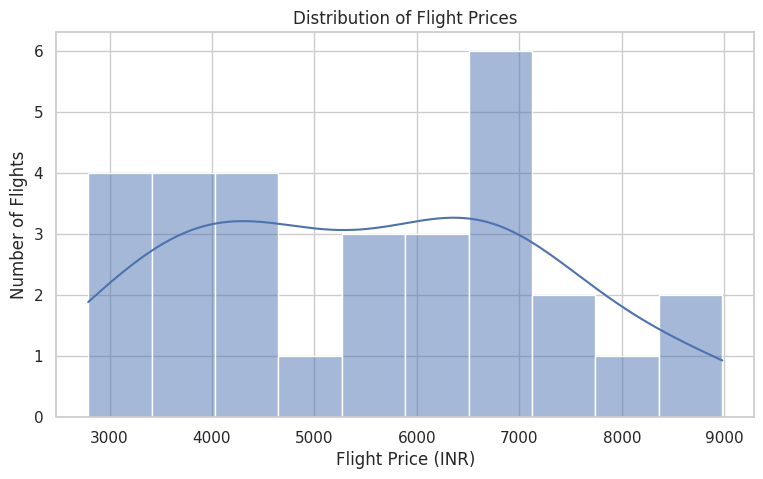

In [16]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=flights_df,
    x="price",
    bins=10,
    kde=True
)

plt.title("Distribution of Flight Prices")
plt.xlabel("Flight Price (INR)")
plt.ylabel("Number of Flights")

plt.show()


**Chart 2 := Average flight price by airline**

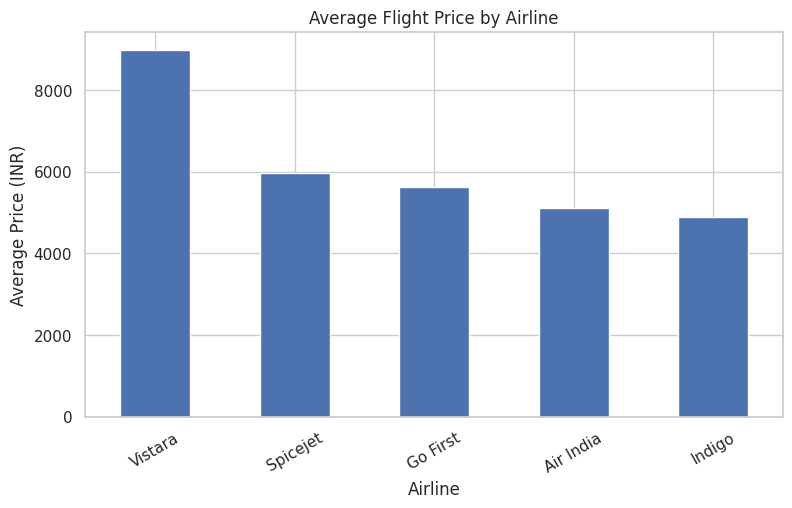

In [17]:
airline_prices = (
    flights_df.groupby("airline")["price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

airline_prices.plot(kind="bar")

plt.title("Average Flight Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Price (INR)")
plt.xticks(rotation=30)

plt.show()


**Chart 3 :- Flight duration distribution**

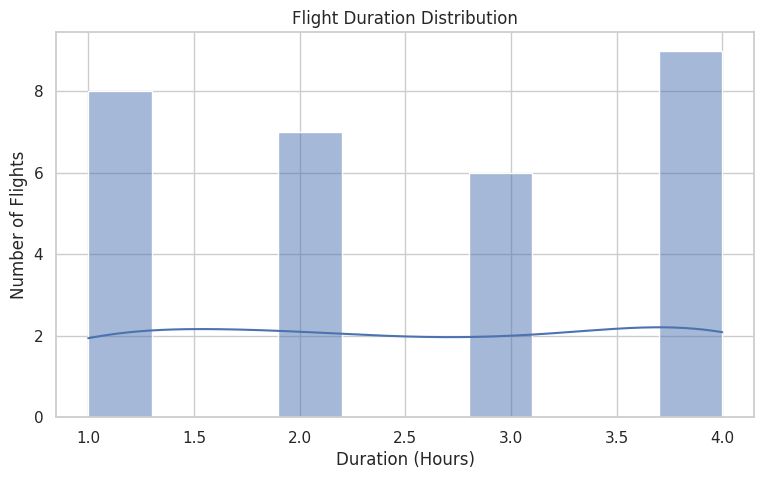

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=flights_df,
    x="duration_hours",
    bins=10,
    kde=True
)

plt.title("Flight Duration Distribution")
plt.xlabel("Duration (Hours)")
plt.ylabel("Number of Flights")

plt.show()


**Hotel dataset analysis**

In [19]:
# STEP 2.9 — Hotel EDA

print("HOTEL DATASET STATISTICS")

display(
    hotels_df[
        ["stars", "price_per_night"]
    ].describe()
)

print("\nHotels by city:")

display(
    hotels_df["city"].value_counts()
)

print("\nAverage hotel price by city:")

hotel_city_summary = (
    hotels_df.groupby("city")
    .agg(
        total_hotels=("hotel_id", "count"),
        average_price=("price_per_night", "mean"),
        average_stars=("stars", "mean")
    )
    .round(2)
    .sort_values("average_price")
)

display(hotel_city_summary)


HOTEL DATASET STATISTICS


,stars,price_per_night
count,40.00000,40.000000
mean,3.42500,4129.800000
std,1.23802,1638.216153
min,2.00000,1232.000000
25%,2.00000,2806.750000
50%,3.50000,4069.500000
75%,5.00000,5652.000000
max,5.00000,6481.000000



Hotels by city:


,count
city,
Delhi,5
Mumbai,5
Goa,5
Bangalore,5
Chennai,5
Hyderabad,5
Kolkata,5
Jaipur,5



Average hotel price by city:


,total_hotels,average_price,average_stars
city,,,
Goa,5,2984.8,3.8
Mumbai,5,3442.8,3.2
Jaipur,5,4072.6,3.4
Chennai,5,4166.4,4.2
Delhi,5,4239.2,3.4
Kolkata,5,4514.8,2.4
Hyderabad,5,4744.6,3.4
Bangalore,5,4873.2,3.6


**Chart 4 :- Hotel prices by city**

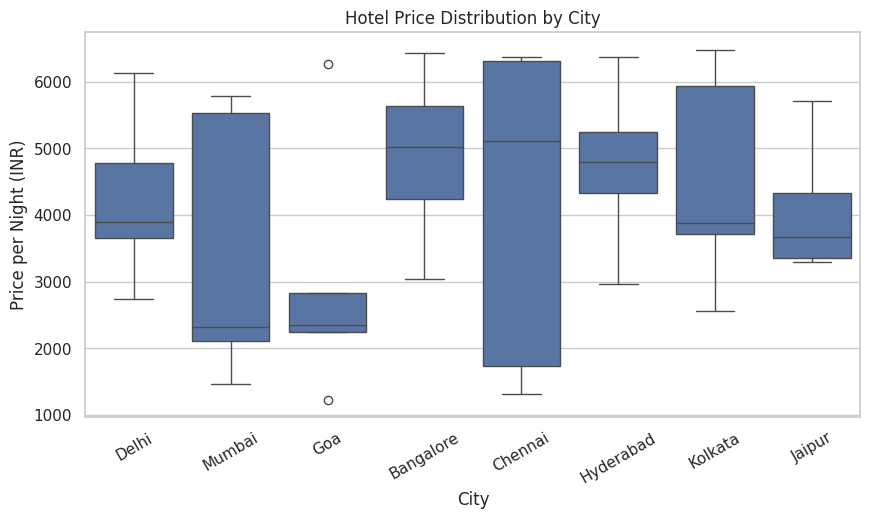

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=hotels_df,
    x="city",
    y="price_per_night"
)

plt.title("Hotel Price Distribution by City")
plt.xlabel("City")
plt.ylabel("Price per Night (INR)")
plt.xticks(rotation=30)

plt.show()


**Chart 5 :- Hotel star rating distribution**

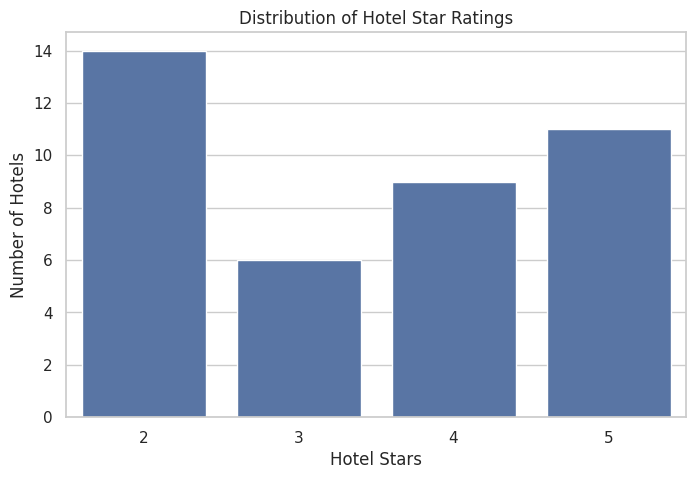

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=hotels_df,
    x="stars"
)

plt.title("Distribution of Hotel Star Ratings")
plt.xlabel("Hotel Stars")
plt.ylabel("Number of Hotels")

plt.show()


**Chart 6 :- Most common hotel amenities**

,Amenity,Count
1,pool,28
0,wifi,25
2,gym,25
5,spa,23
3,breakfast,20
4,parking,17


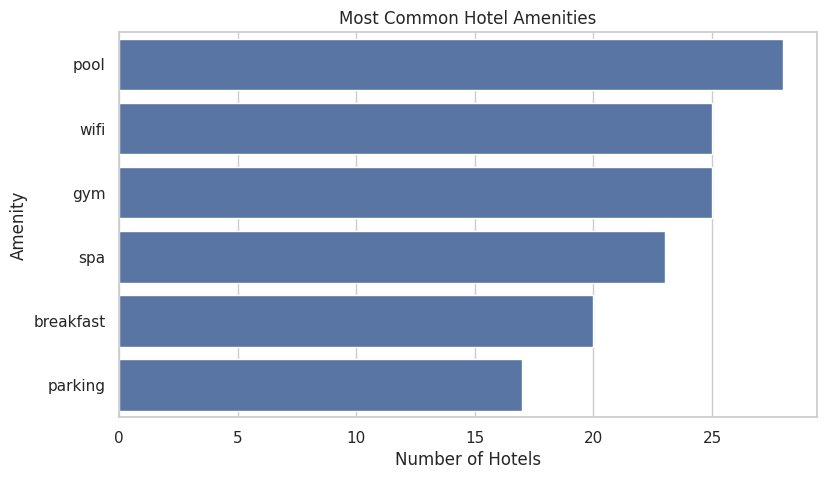

In [22]:
from collections import Counter

amenity_counts = Counter()

for amenities in hotels_df["amenities"]:
    amenity_counts.update(amenities)

amenity_df = pd.DataFrame(
    amenity_counts.items(),
    columns=["Amenity", "Count"]
).sort_values("Count", ascending=False)

display(amenity_df)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=amenity_df,
    x="Count",
    y="Amenity"
)

plt.title("Most Common Hotel Amenities")
plt.xlabel("Number of Hotels")
plt.ylabel("Amenity")

plt.show()


**Tourist places dataset analysis**

In [23]:
# STEP 2.10 — Tourist places EDA

print("TOURIST PLACES STATISTICS")

display(
    places_df["rating"].describe()
)

print("\nPlaces by city:")

display(
    places_df["city"].value_counts()
)

print("\nPlaces by category:")

display(
    places_df["type"].value_counts()
)

print("\nAverage tourist rating by city:")

city_rating = (
    places_df.groupby("city")["rating"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

display(city_rating)


TOURIST PLACES STATISTICS


,rating
count,40.000000
mean,4.175000
std,0.394676
min,3.500000
25%,3.875000
50%,4.200000
75%,4.500000
max,4.900000



Places by city:


,count
city,
Delhi,5
Mumbai,5
Goa,5
Bangalore,5
Chennai,5
Hyderabad,5
Kolkata,5
Jaipur,5



Places by category:


,count
type,
park,8
market,7
museum,6
temple,5
lake,4
fort,4
beach,4
monument,2



Average tourist rating by city:


,rating
city,
Kolkata,4.66
Goa,4.22
Hyderabad,4.22
Delhi,4.20
Bangalore,4.10
Chennai,4.10
Jaipur,4.04
Mumbai,3.86


**Chart 7 :- Tourist places by city**

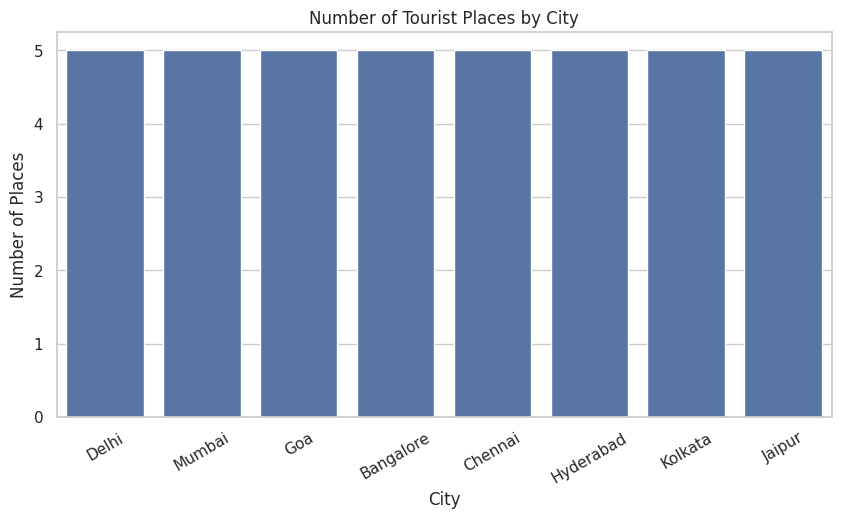

In [24]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=places_df,
    x="city",
    order=places_df["city"].value_counts().index
)

plt.title("Number of Tourist Places by City")
plt.xlabel("City")
plt.ylabel("Number of Places")
plt.xticks(rotation=30)

plt.show()


**Chart 8 :- Tourist attraction ratings**

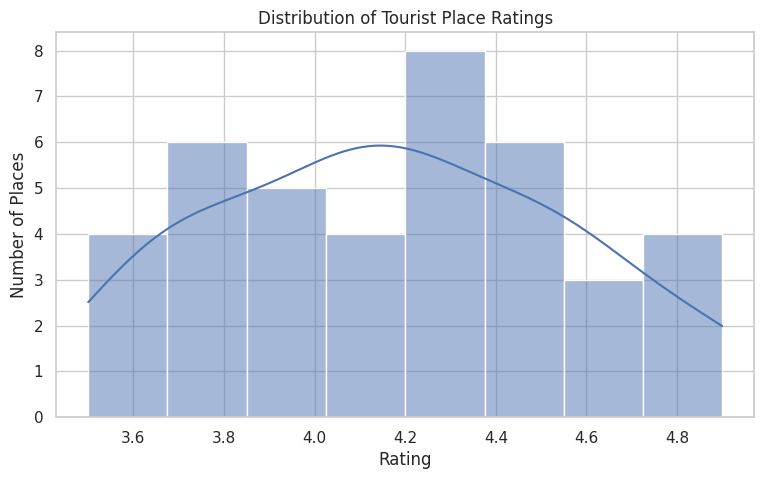

In [25]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=places_df,
    x="rating",
    bins=8,
    kde=True
)

plt.title("Distribution of Tourist Place Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Places")

plt.show()


**Chart 9 :- Average rating by tourist category**

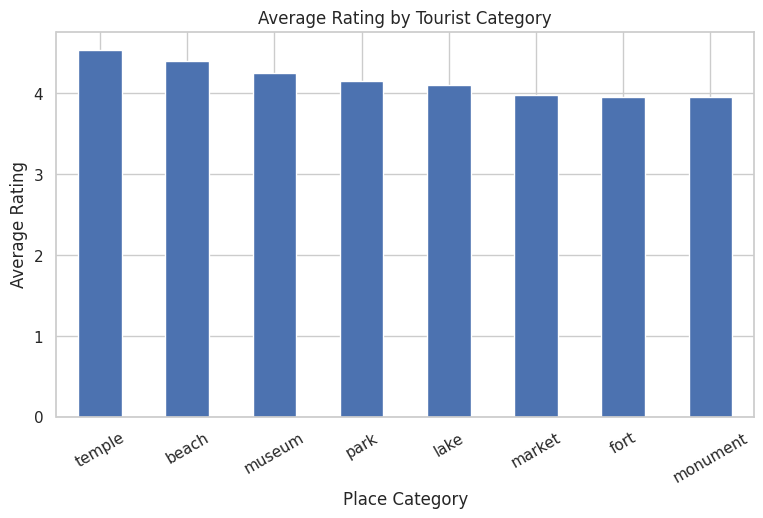

In [26]:
category_rating = (
    places_df.groupby("type")["rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

category_rating.plot(kind="bar")

plt.title("Average Rating by Tourist Category")
plt.xlabel("Place Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=30)

plt.show()


In [27]:
# STEP 2.11 — Outlier detection using IQR

def detect_outliers(df, column):

    series = df[column].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"\nOutlier report for {column}")
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Number of outliers:", len(outliers))

    return outliers


flight_price_outliers = detect_outliers(
    flights_df, "price"
)

hotel_price_outliers = detect_outliers(
    hotels_df, "price_per_night"
)

place_rating_outliers = detect_outliers(
    places_df, "rating"
)



Outlier report for price
Lower limit: 81.5
Upper limit: 10767.5
Number of outliers: 0

Outlier report for price_per_night
Lower limit: -1461.12
Upper limit: 9919.88
Number of outliers: 0

Outlier report for rating
Lower limit: 2.94
Upper limit: 5.44
Number of outliers: 0


In [28]:
# STEP 2.12 — Save cleaned datasets

OUTPUT_DIR = Path("/content/cleaned_data")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save CSV files
flights_df.to_csv(
    OUTPUT_DIR / "cleaned_flights.csv",
    index=False
)

hotels_df.to_csv(
    OUTPUT_DIR / "cleaned_hotels.csv",
    index=False
)

places_df.to_csv(
    OUTPUT_DIR / "cleaned_places.csv",
    index=False
)

# Save JSON files as well
# Convert datetime columns into strings for JSON compatibility

flights_json_df = flights_df.copy()

for col in ["departure_time", "arrival_time"]:
    flights_json_df[col] = (
        flights_json_df[col].astype("string")
    )

flights_json_df.to_json(
    OUTPUT_DIR / "cleaned_flights.json",
    orient="records",
    indent=4
)

hotels_df.to_json(
    OUTPUT_DIR / "cleaned_hotels.json",
    orient="records",
    indent=4
)

places_df.to_json(
    OUTPUT_DIR / "cleaned_places.json",
    orient="records",
    indent=4
)

print("All cleaned datasets saved successfully!")

print("\nSaved files:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)


All cleaned datasets saved successfully!

Saved files:
cleaned_hotels.json
cleaned_flights.json
cleaned_places.csv
cleaned_hotels.csv
cleaned_flights.csv
cleaned_places.json


In [29]:
# STEP 2.13 — Download cleaned dataset ZIP

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/cleaned_travel_datasets",
    "zip",
    OUTPUT_DIR
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# STEP 2.14 — Final data quality report

def get_duplicate_count(df):
    temp_df = df.copy()
    for col in temp_df.columns:
        temp_df[col] = temp_df[col].apply(
            lambda x: str(x) if isinstance(x, (list, dict)) else x
        )
    return temp_df.duplicated().sum()

final_report = pd.DataFrame([
    {
        "Dataset": name,
        "Total_Rows": len(df),
        "Total_Columns": len(df.columns),
        "Missing_Values": df.isnull().sum().sum(),
        "Duplicate_Rows": get_duplicate_count(df)
    }
    for name, df in {
        "Flights": flights_df,
        "Hotels": hotels_df,
        "Places": places_df
    }.items()
])

display(final_report)

print("\nSTEP 2 COMPLETED SUCCESSFULLY!")

,Dataset,Total_Rows,Total_Columns,Missing_Values,Duplicate_Rows
0,Flights,30,8,0,0
1,Hotels,40,6,0,0
2,Places,40,5,0,0



STEP 2 COMPLETED SUCCESSFULLY!


In [31]:
# STEP 3.1 — Import required libraries

import sqlite3
import json
import pandas as pd
import os

print("SQLite libraries imported successfully!")

SQLite libraries imported successfully!


In [32]:
# STEP 3.2 — Create SQLite database

DB_PATH = "/content/travel_planner.db"

# Establish database connection
conn = sqlite3.connect(DB_PATH)

# Create cursor
cursor = conn.cursor()

print("Database created successfully!")
print("Database location:", DB_PATH)

Database created successfully!
Database location: /content/travel_planner.db


In [33]:
# STEP 3.3 — Create database tables

cursor.execute("""
CREATE TABLE IF NOT EXISTS flights (
    flight_id TEXT PRIMARY KEY,
    airline TEXT,
    origin TEXT,
    destination TEXT,
    departure_time TEXT,
    arrival_time TEXT,
    price REAL,
    duration_hours REAL
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS hotels (
    hotel_id TEXT PRIMARY KEY,
    name TEXT,
    city TEXT,
    stars REAL,
    price_per_night REAL,
    amenities TEXT
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS places (
    place_id TEXT PRIMARY KEY,
    name TEXT,
    city TEXT,
    type TEXT,
    rating REAL
)
""")

conn.commit()

print("All three database tables created successfully!")

All three database tables created successfully!


In [34]:
# STEP 3.4 — Prepare cleaned data for SQLite

def prepare_value(value):

    # Convert missing values into SQL NULL
    if value is None:
        return None

    if isinstance(value, (list, dict)):
        return json.dumps(value)

    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    # Convert NumPy scalar values into normal Python values
    if hasattr(value, "item"):
        return value.item()

    return value


def dataframe_to_records(df):
    return [
        tuple(prepare_value(value) for value in row)
        for row in df.itertuples(index=False, name=None)
    ]


print("Data preparation completed!")

Data preparation completed!


In [35]:
# STEP 3.4 — Insert records into database

# Clear old records to avoid duplicate primary-key errors
cursor.execute("DELETE FROM flights")
cursor.execute("DELETE FROM hotels")
cursor.execute("DELETE FROM places")

# Flights
flight_records = dataframe_to_records(flights_df)

cursor.executemany("""
INSERT INTO flights (
    flight_id, airline, origin, destination,
    departure_time, arrival_time, price, duration_hours
)
VALUES (?, ?, ?, ?, ?, ?, ?, ?)
""", flight_records)

# Hotels
hotel_records = dataframe_to_records(hotels_df)

cursor.executemany("""
INSERT INTO hotels (
    hotel_id, name, city, stars, price_per_night, amenities
)
VALUES (?, ?, ?, ?, ?, ?)
""", hotel_records)

# Tourist places
place_records = dataframe_to_records(places_df)

cursor.executemany("""
INSERT INTO places (
    place_id, name, city, type, rating
)
VALUES (?, ?, ?, ?, ?)
""", place_records)

# Save database changes
conn.commit()

print("All cleaned records inserted successfully!")

All cleaned records inserted successfully!


In [36]:
# STEP 3.5 — Verify inserted records

tables = ["flights", "hotels", "places"]

for table in tables:

    result = pd.read_sql_query(
        f"SELECT COUNT(*) AS total_records FROM {table}",
        conn
    )

    print(f"{table.upper()}: {result.iloc[0]['total_records']} records")

FLIGHTS: 30 records
HOTELS: 40 records
PLACES: 40 records


In [37]:
# Display all flights

query = """
SELECT * FROM flights
"""

display(pd.read_sql_query(query, conn))

,flight_id,airline,origin,destination,departure_time,arrival_time,price,duration_hours
0,FL0001,Indigo,Hyderabad,Delhi,2025-01-04T11:32:00,2025-01-04T15:32:00,2907.0,4.0
1,FL0002,Air India,Delhi,Kolkata,2025-11-26T05:34:00,2025-11-26T09:34:00,3779.0,4.0
2,FL0003,Spicejet,Chennai,Hyderabad,2025-06-03T00:26:00,2025-06-03T01:26:00,5473.0,1.0
3,FL0004,Air India,Bangalore,Mumbai,2025-05-13T13:18:00,2025-05-13T17:18:00,4764.0,4.0
4,FL0005,Air India,Chennai,Bangalore,2025-02-08T03:08:00,2025-02-08T05:08:00,3695.0,2.0
5,FL0006,Spicejet,Goa,Bangalore,2025-12-27T22:52:00,2025-12-28T02:52:00,8255.0,4.0
6,FL0007,Spicejet,Kolkata,Jaipur,2025-04-17T13:11:00,2025-04-17T14:11:00,4340.0,1.0
7,FL0008,Indigo,Goa,Jaipur,2025-12-11T21:38:00,2025-12-11T22:38:00,6755.0,1.0
8,FL0009,Spicejet,Bangalore,Delhi,2025-01-25T06:00:00,2025-01-25T09:00:00,8603.0,3.0
9,FL0010,Indigo,Chennai,Mumbai,2025-02-27T08:06:00,2025-02-27T12:06:00,4013.0,4.0


In [38]:
# Search flights by route

query = """
SELECT flight_id, airline, origin, destination, price
FROM flights
WHERE LOWER(origin) = 'hyderabad'
AND LOWER(destination) = 'delhi'
ORDER BY price ASC
"""

display(pd.read_sql_query(query, conn))

,flight_id,airline,origin,destination,price
0,FL0001,Indigo,Hyderabad,Delhi,2907.0


In [39]:
# Find the five cheapest flights

query = """
SELECT airline, origin, destination, price
FROM flights
ORDER BY price ASC
LIMIT 5
"""

display(pd.read_sql_query(query, conn))

,airline,origin,destination,price
0,Go First,Mumbai,Hyderabad,2792.0
1,Indigo,Hyderabad,Delhi,2907.0
2,Air India,Hyderabad,Kolkata,2909.0
3,Spicejet,Mumbai,Goa,3304.0
4,Air India,Chennai,Bangalore,3695.0


In [40]:
# Search hotels by city

query = """
SELECT name, city, stars, price_per_night
FROM hotels
WHERE LOWER(city) = 'goa'
ORDER BY price_per_night ASC
"""

display(pd.read_sql_query(query, conn))

,name,city,stars,price_per_night
0,Royal Heritage,Goa,5.0,1232.0
1,Budget Stay Inn,Goa,4.0,2248.0
2,Green Leaf Resort,Goa,3.0,2357.0
3,Comfort Suites,Goa,5.0,2828.0
4,Green Leaf Resort,Goa,2.0,6259.0


In [41]:
# Find highly rated hotels

query = """
SELECT name, city, stars, price_per_night
FROM hotels
WHERE stars >= 4
ORDER BY stars DESC
"""

display(pd.read_sql_query(query, conn))

,name,city,stars,price_per_night
0,Comfort Suites,Delhi,5.0,3650.0
1,Comfort Suites,Mumbai,5.0,5787.0
2,Budget Stay Inn,Mumbai,5.0,5536.0
3,Comfort Suites,Goa,5.0,2828.0
4,Royal Heritage,Goa,5.0,1232.0
5,Green Leaf Resort,Bangalore,5.0,5018.0
6,Sea View Resort,Chennai,5.0,6372.0
7,Royal Heritage,Chennai,5.0,6303.0
8,City Center Hotel,Hyderabad,5.0,4332.0
9,Blue Lagoon Resort,Hyderabad,5.0,5247.0


In [42]:
# Search tourist places by city

query = """
SELECT name, city, type, rating
FROM places
WHERE LOWER(city) = 'jaipur'
ORDER BY rating DESC
"""

display(pd.read_sql_query(query, conn))

,name,city,type,rating
0,Scenic Park,Jaipur,park,4.6
1,Beautiful Fort,Jaipur,park,4.5
2,Beautiful Park,Jaipur,park,3.7
3,Famous Park,Jaipur,fort,3.7
4,Scenic Temple,Jaipur,monument,3.7


In [43]:
# Top 10 tourist attractions

query = """
SELECT name, city, type, rating
FROM places
ORDER BY rating DESC
LIMIT 10
"""

display(pd.read_sql_query(query, conn))

,name,city,type,rating
0,Famous Fort,Kolkata,beach,4.9
1,Historic Temple,Kolkata,temple,4.9
2,Scenic Museum,Kolkata,temple,4.9
3,Scenic Temple,Chennai,beach,4.8
4,Famous Fort,Delhi,lake,4.6
5,Popular Lake,Hyderabad,park,4.6
6,Scenic Park,Jaipur,park,4.6
7,Popular Museum,Delhi,lake,4.5
8,Famous Park,Goa,museum,4.5
9,Historic Fort,Bangalore,temple,4.5


In [44]:
# Hotel availability by city

query = """
SELECT city, COUNT(*) AS total_hotels
FROM hotels
GROUP BY city
ORDER BY total_hotels DESC
"""

display(pd.read_sql_query(query, conn))

,city,total_hotels
0,Mumbai,5
1,Kolkata,5
2,Jaipur,5
3,Hyderabad,5
4,Goa,5
5,Delhi,5
6,Chennai,5
7,Bangalore,5


In [45]:
# STEP 3.7 — Reusable SQL function

def run_sql(query):

    try:
        result = pd.read_sql_query(query, conn)
        return result

    except Exception as e:
        print("SQL Error:", e)
        return None


# Example: Search hotels in Mumbai

result = run_sql("""
SELECT *
FROM hotels
WHERE LOWER(city) = 'mumbai'
""")

display(result)

,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0006,Green Leaf Resort,Mumbai,2.0,1471.0,"[""gym"", ""parking"", ""pool""]"
1,HOT0007,Budget Stay Inn,Mumbai,2.0,2316.0,"[""pool"", ""breakfast"", ""spa"", ""gym"", ""wifi""]"
2,HOT0008,Royal Heritage,Mumbai,2.0,2104.0,"[""gym"", ""breakfast"", ""pool"", ""wifi""]"
3,HOT0009,Comfort Suites,Mumbai,5.0,5787.0,"[""breakfast"", ""spa"", ""gym"", ""wifi""]"
4,HOT0010,Budget Stay Inn,Mumbai,5.0,5536.0,"[""breakfast"", ""gym"", ""spa"", ""wifi""]"


In [46]:
# STEP 3.8 — Inspect database schema

for table in ["flights", "hotels", "places"]:

    print("\nTABLE:", table.upper())

    schema = pd.read_sql_query(
        f"PRAGMA table_info({table})",
        conn
    )

    display(schema[["name", "type", "pk"]])


TABLE: FLIGHTS


,name,type,pk
0,flight_id,TEXT,1
1,airline,TEXT,0
2,origin,TEXT,0
3,destination,TEXT,0
4,departure_time,TEXT,0
5,arrival_time,TEXT,0
6,price,REAL,0
7,duration_hours,REAL,0



TABLE: HOTELS


,name,type,pk
0,hotel_id,TEXT,1
1,name,TEXT,0
2,city,TEXT,0
3,stars,REAL,0
4,price_per_night,REAL,0
5,amenities,TEXT,0



TABLE: PLACES


,name,type,pk
0,place_id,TEXT,1
1,name,TEXT,0
2,city,TEXT,0
3,type,TEXT,0
4,rating,REAL,0


In [47]:
# STEP 3.9 — Save database

conn.commit()
conn.close()

print("Database saved successfully!")
print("File:", DB_PATH)
print("File exists:", os.path.exists(DB_PATH))

Database saved successfully!
File: /content/travel_planner.db
File exists: True


In [48]:
# Download SQLite database from Google Colab

from google.colab import files

files.download("/content/travel_planner.db")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
import sqlite3

DB_PATH = "/content/travel_planner.db"

conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

print("Database connected successfully!")

Database connected successfully!


In [50]:
# STEP 4.1 — Connect to SQLite database

import sqlite3
import pandas as pd
import json
import os

DB_PATH = "/content/travel_planner.db"

if not os.path.exists(DB_PATH):
    raise FileNotFoundError(
        "Database not found. Please upload travel_planner.db."
    )

conn = sqlite3.connect(DB_PATH)

print("Database connected successfully!")

Database connected successfully!


In [51]:
# STEP 4.2 — Database query function

def execute_query(query, params=()):

    try:
        result = pd.read_sql_query(
            query,
            conn,
            params=params
        )

        return result

    except Exception as error:
        print("Database error:", error)
        return pd.DataFrame()

In [52]:
# STEP 4.3 — Flight Search Tool

def search_flights(
    origin,
    destination,
    max_price=None
):

    query = """
    SELECT
        flight_id,
        airline,
        origin,
        destination,
        departure_time,
        arrival_time,
        price,
        duration_hours

    FROM flights

    WHERE LOWER(TRIM(origin)) = LOWER(TRIM(?))
    AND LOWER(TRIM(destination)) = LOWER(TRIM(?))
    """

    params = [origin, destination]

    if max_price is not None:
        query += " AND price <= ?"
        params.append(max_price)

    query += " ORDER BY price ASC"

    result = execute_query(query, tuple(params))

    if result.empty:
        print("No matching flights found.")
    else:
        print(f"Found {len(result)} matching flights.")

    return result

In [53]:
# STEP 4.4 — Hotel Search Tool

def search_hotels(
    city,
    max_price=None,
    min_stars=None
):

    query = """
    SELECT
        hotel_id,
        name,
        city,
        stars,
        price_per_night,
        amenities

    FROM hotels

    WHERE LOWER(TRIM(city)) = LOWER(TRIM(?))
    """

    params = [city]

    if max_price is not None:
        query += " AND price_per_night <= ?"
        params.append(max_price)

    if min_stars is not None:
        query += " AND stars >= ?"
        params.append(min_stars)

    query += " ORDER BY price_per_night ASC"

    result = execute_query(query, tuple(params))

    if result.empty:
        print("No matching hotels found.")
    else:
        print(f"Found {len(result)} matching hotels.")

        # Convert JSON amenities into readable Python lists
        result["amenities"] = result["amenities"].apply(
            lambda x: json.loads(x) if isinstance(x, str) else x
        )

    return result

In [54]:
# STEP 4.5 — Tourist Places Search Tool

def search_places(
    city,
    place_type=None,
    min_rating=None
):

    query = """
    SELECT
        place_id,
        name,
        city,
        type,
        rating

    FROM places

    WHERE LOWER(TRIM(city)) = LOWER(TRIM(?))
    """

    params = [city]

    if place_type is not None:
        query += " AND LOWER(TRIM(type)) = LOWER(TRIM(?))"
        params.append(place_type)

    if min_rating is not None:
        query += " AND rating >= ?"
        params.append(min_rating)

    query += " ORDER BY rating DESC"

    result = execute_query(query, tuple(params))

    if result.empty:
        print("No matching tourist places found.")
    else:
        print(f"Found {len(result)} tourist places.")

    return result

In [55]:
# Search tourist attractions in Jaipur

place_results = search_places(
    city="Jaipur",
    min_rating=3.5
)

display(place_results)

Found 5 tourist places.


,place_id,name,city,type,rating
0,PLC0040,Scenic Park,Jaipur,park,4.6
1,PLC0037,Beautiful Fort,Jaipur,park,4.5
2,PLC0036,Beautiful Park,Jaipur,park,3.7
3,PLC0038,Famous Park,Jaipur,fort,3.7
4,PLC0039,Scenic Temple,Jaipur,monument,3.7


In [56]:
# Search beaches in Goa

beach_results = search_places(
    city="Goa",
    place_type="beach",
    min_rating=3
)

display(beach_results)

No matching tourist places found.


,place_id,name,city,type,rating


In [57]:
# STEP 4.6 — Complete search tools testing

print("=" * 50)
print("TRAVEL PLANNER SEARCH TEST")
print("=" * 50)

# Flight search
print("\n1. FLIGHT SEARCH")

flights = search_flights(
    "Hyderabad",
    "Delhi",
    10000
)

display(flights)

# Hotel search
print("\n2. HOTEL SEARCH")

hotels = search_hotels(
    "Goa",
    10000,
    3
)

display(hotels)

# Tourist places search
print("\n3. TOURIST PLACES SEARCH")

places = search_places(
    "Jaipur",
    min_rating=3.5
)

display(places)

print("\nAll search tests completed!")

TRAVEL PLANNER SEARCH TEST

1. FLIGHT SEARCH
Found 1 matching flights.


,flight_id,airline,origin,destination,departure_time,arrival_time,price,duration_hours
0,FL0001,Indigo,Hyderabad,Delhi,2025-01-04T11:32:00,2025-01-04T15:32:00,2907.0,4.0



2. HOTEL SEARCH
Found 4 matching hotels.


,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0014,Royal Heritage,Goa,5.0,1232.0,"[wifi, parking, breakfast, pool]"
1,HOT0015,Budget Stay Inn,Goa,4.0,2248.0,"[wifi, spa, pool, gym]"
2,HOT0012,Green Leaf Resort,Goa,3.0,2357.0,"[spa, gym, pool, breakfast]"
3,HOT0011,Comfort Suites,Goa,5.0,2828.0,"[spa, pool, wifi, gym]"



3. TOURIST PLACES SEARCH
Found 5 tourist places.


,place_id,name,city,type,rating
0,PLC0040,Scenic Park,Jaipur,park,4.6
1,PLC0037,Beautiful Fort,Jaipur,park,4.5
2,PLC0036,Beautiful Park,Jaipur,park,3.7
3,PLC0038,Famous Park,Jaipur,fort,3.7
4,PLC0039,Scenic Temple,Jaipur,monument,3.7



All search tests completed!


In [58]:
# STEP 4.7 — Unified Travel Search

def travel_search(
    origin,
    destination,
    max_flight_price,
    max_hotel_price,
    min_hotel_stars,
    min_place_rating
):

    print("\n========== FLIGHT RESULTS ==========")

    flight_data = search_flights(
        origin,
        destination,
        max_flight_price
    )

    display(flight_data)

    print("\n========== HOTEL RESULTS ==========")

    hotel_data = search_hotels(
        destination,
        max_hotel_price,
        min_hotel_stars
    )

    display(hotel_data)

    print("\n========== TOURIST PLACES ==========")

    place_data = search_places(
        destination,
        min_rating=min_place_rating
    )

    display(place_data)

    return {
        "flights": flight_data,
        "hotels": hotel_data,
        "places": place_data
    }

In [59]:
# Example travel search

travel_results = travel_search(
    origin="Hyderabad",
    destination="Goa",
    max_flight_price=10000,
    max_hotel_price=8000,
    min_hotel_stars=3,
    min_place_rating=3.5
)


========== FLIGHT RESULTS ==========
Found 1 matching flights.


,flight_id,airline,origin,destination,departure_time,arrival_time,price,duration_hours
0,FL0016,Air India,Hyderabad,Goa,2025-08-28T14:26:00,2025-08-28T18:26:00,7299.0,4.0



========== HOTEL RESULTS ==========
Found 4 matching hotels.


,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0014,Royal Heritage,Goa,5.0,1232.0,"[wifi, parking, breakfast, pool]"
1,HOT0015,Budget Stay Inn,Goa,4.0,2248.0,"[wifi, spa, pool, gym]"
2,HOT0012,Green Leaf Resort,Goa,3.0,2357.0,"[spa, gym, pool, breakfast]"
3,HOT0011,Comfort Suites,Goa,5.0,2828.0,"[spa, pool, wifi, gym]"



========== TOURIST PLACES ==========
Found 5 tourist places.


,place_id,name,city,type,rating
0,PLC0012,Famous Park,Goa,museum,4.5
1,PLC0014,Beautiful Park,Goa,fort,4.3
2,PLC0011,Popular Lake,Goa,museum,4.2
3,PLC0013,Historic Park,Goa,fort,4.1
4,PLC0015,Beautiful Lake,Goa,market,4.0


In [60]:
# STEP 4.8 — Verify all search tools

print("FLIGHT TOOL:", callable(search_flights))
print("HOTEL TOOL:", callable(search_hotels))
print("PLACES TOOL:", callable(search_places))
print("UNIFIED TOOL:", callable(travel_search))

print("\nStep 4 search tools are ready!")

FLIGHT TOOL: True
HOTEL TOOL: True
PLACES TOOL: True
UNIFIED TOOL: True

Step 4 search tools are ready!


In [61]:
# STEP 5.1 — Import weather API libraries

import requests
import pandas as pd
import json

print("Weather API libraries imported successfully!")

Weather API libraries imported successfully!


In [62]:
# STEP 5.3 — City Geocoding Function

def get_city_coordinates(city):

    url = "https://geocoding-api.open-meteo.com/v1/search"

    params = {
        "name": city,
        "count": 10,
        "language": "en",
        "format": "json"
    }

    try:

        response = requests.get(
            url,
            params=params,
            timeout=20
        )

        response.raise_for_status()

        data = response.json()

        if not data.get("results"):
            print("City not found:", city)
            return None

        # Prefer a matching city in India
        results = data["results"]

        india_results = [
            item for item in results
            if item.get("country_code") == "IN"
        ]

        selected = india_results[0] if india_results else results[0]

        location = {
            "city": selected["name"],
            "country": selected.get("country", "Unknown"),
            "latitude": selected["latitude"],
            "longitude": selected["longitude"],
            "timezone": selected.get("timezone", "Unknown")
        }

        return location

    except requests.exceptions.RequestException as error:

        print("Geocoding API error:", error)
        return None

In [63]:
# Test city coordinates

location = get_city_coordinates("Goa")

print(location)

{'city': 'Genoa', 'country': 'Italy', 'latitude': 44.40478, 'longitude': 8.94439, 'timezone': 'Europe/Rome'}


In [64]:
# STEP 5.4 — Weather Code Mapping

WEATHER_CODES = {

    0: "Clear sky",
    1: "Mainly clear",
    2: "Partly cloudy",
    3: "Overcast",

    45: "Fog",
    48: "Depositing rime fog",

    51: "Light drizzle",
    53: "Moderate drizzle",
    55: "Dense drizzle",

    61: "Slight rain",
    63: "Moderate rain",
    65: "Heavy rain",

    71: "Slight snowfall",
    73: "Moderate snowfall",
    75: "Heavy snowfall",

    80: "Slight rain showers",
    81: "Moderate rain showers",
    82: "Violent rain showers",

    95: "Thunderstorm",
    96: "Thunderstorm with slight hail",
    99: "Thunderstorm with heavy hail"
}


def get_weather_description(code):

    return WEATHER_CODES.get(
        code,
        "Unknown weather condition"
    )

In [65]:
# STEP 5.5 — Live Weather API Function

def get_live_weather(city):

    # First, find city coordinates
    location = get_city_coordinates(city)

    if location is None:
        return None

    latitude = location["latitude"]
    longitude = location["longitude"]

    # Open-Meteo forecast endpoint
    url = "https://api.open-meteo.com/v1/forecast"

    params = {

        "latitude": latitude,
        "longitude": longitude,

        "current": (
            "temperature_2m,"
            "relative_humidity_2m,"
            "apparent_temperature,"
            "is_day,"
            "precipitation,"
            "weather_code,"
            "wind_speed_10m"
        ),

        "daily": (
            "weather_code,"
            "temperature_2m_max,"
            "temperature_2m_min,"
            "precipitation_probability_max"
        ),

        "forecast_days": 5,
        "timezone": "auto"
    }

    try:

        response = requests.get(
            url,
            params=params,
            timeout=30
        )

        response.raise_for_status()

        data = response.json()

        current = data.get("current")

        if not current:
            print("Current weather data unavailable.")
            return None

        # Current weather details
        current_weather = {

            "city": location["city"],
            "country": location["country"],

            "temperature": current.get("temperature_2m"),

            "feels_like": current.get("apparent_temperature"),

            "humidity": current.get("relative_humidity_2m"),

            "wind_speed": current.get("wind_speed_10m"),

            "precipitation": current.get("precipitation"),

            "condition": get_weather_description(
                current.get("weather_code")
            ),

            "observation_time": current.get("time"),

            "timezone": data.get("timezone")
        }

        # Forecast details
        daily = data.get("daily", {})

        forecast_df = pd.DataFrame({

            "date": daily.get("time", []),

            "condition": [
                get_weather_description(code)
                for code in daily.get("weather_code", [])
            ],

            "max_temperature": daily.get(
                "temperature_2m_max", []
            ),

            "min_temperature": daily.get(
                "temperature_2m_min", []
            ),

            "rain_probability": daily.get(
                "precipitation_probability_max", []
            )
        })

        return {

            "location": location,

            "current_weather": current_weather,

            "forecast": forecast_df,

            "raw_data": data
        }

    except requests.exceptions.RequestException as error:

        print("Weather API error:", error)
        return None

    except (KeyError, TypeError, ValueError) as error:

        print("Weather data processing error:", error)
        return None

In [66]:
# STEP 5.6 — Test Live Weather

weather_data = get_live_weather("Goa")

if weather_data:

    print("=" * 45)
    print("LIVE WEATHER REPORT")
    print("=" * 45)

    current = weather_data["current_weather"]

    for key, value in current.items():

        print(f"{key}: {value}")

    print("\nFIVE-DAY WEATHER FORECAST")

    display(weather_data["forecast"])

else:

    print("Unable to retrieve weather information.")

Weather API error: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Read timed out. (read timeout=30)
Unable to retrieve weather information.


In [67]:
# STEP 5.7 — Weather-Based Travel Recommendations

def weather_recommendation(weather_data):

    if weather_data is None:
        return "Weather information unavailable."

    forecast = weather_data["forecast"]

    if forecast.empty:
        return "Forecast information unavailable."

    recommendations = []

    for _, row in forecast.iterrows():

        rain = row["rain_probability"]

        condition = row["condition"]

        if pd.isna(rain):
            suggestion = "Check local weather before planning."

        elif condition in [
            "Thunderstorm",
            "Thunderstorm with slight hail",
            "Thunderstorm with heavy hail"
        ]:
            suggestion = "Prefer indoor activities and monitor weather alerts."

        elif rain >= 60:
            suggestion = "Prefer indoor attractions or flexible activities."

        elif rain >= 30:
            suggestion = "Keep an alternative indoor activity available."

        else:
            suggestion = "Outdoor sightseeing may be suitable."

        recommendations.append({

            "date": row["date"],

            "weather": condition,

            "rain_probability": rain,

            "recommendation": suggestion

        })

    return pd.DataFrame(recommendations)

In [68]:
# STEP 5.7 — Display travel recommendations

recommendations = weather_recommendation(weather_data)

if isinstance(recommendations, pd.DataFrame):

    display(recommendations)

else:

    print(recommendations)

Weather information unavailable.


In [69]:
# STEP 5.8 — Travel Weather Search Tool

def travel_weather_tool(city):

    weather = get_live_weather(city)

    if weather is None:
        return None

    recommendation = weather_recommendation(weather)

    print("\nWEATHER FOR:", city)

    display(
        pd.DataFrame([weather["current_weather"]])
    )

    print("\nTRAVEL RECOMMENDATIONS")

    if isinstance(recommendation, pd.DataFrame):
        display(recommendation)
    else:
        print(recommendation)

    return weather

In [133]:
# STEP 5.8 — Final weather tool test

goa_weather = travel_weather_tool("Goa")


WEATHER FOR: Goa


,city,country,temperature,feels_like,humidity,wind_speed,precipitation,condition,observation_time,timezone
0,Genoa,Italy,13.4,13.0,91,6.5,0.2,Slight rain,2026-11-22T09:00,Europe/Rome



TRAVEL RECOMMENDATIONS


,date,weather,rain_probability,recommendation
0,2026-11-22,Heavy rain,100,Prefer indoor attractions or flexible activities.
1,2026-11-23,Overcast,3,Outdoor sightseeing may be suitable.
2,2026-11-24,Slight rain showers,61,Prefer indoor attractions or flexible activities.
3,2026-11-25,Slight rain showers,100,Prefer indoor attractions or flexible activities.
4,2026-11-26,Overcast,54,Keep an alternative indoor activity available.


In [134]:
mumbai_weather = travel_weather_tool("Mumbai")


WEATHER FOR: Mumbai


,city,country,temperature,feels_like,humidity,wind_speed,precipitation,condition,observation_time,timezone
0,Mumbai,India,31.7,33.1,35,6.8,0.0,Clear sky,2026-11-22T13:30,Asia/Kolkata



TRAVEL RECOMMENDATIONS


,date,weather,rain_probability,recommendation
0,2026-11-22,Clear sky,0,Outdoor sightseeing may be suitable.
1,2026-11-23,Clear sky,0,Outdoor sightseeing may be suitable.
2,2026-11-24,Mainly clear,0,Outdoor sightseeing may be suitable.
3,2026-11-25,Overcast,0,Outdoor sightseeing may be suitable.
4,2026-11-26,Clear sky,0,Outdoor sightseeing may be suitable.


In [72]:
# STEP 5.9 — Weather integration verification

print("WEATHER TOOL:", callable(get_live_weather))

print(
    "GEOCODING TOOL:",
    callable(get_city_coordinates)
)

print(
    "RECOMMENDATION TOOL:",
    callable(weather_recommendation)
)

print(
    "TRAVEL WEATHER TOOL:",
    callable(travel_weather_tool)
)

print("\nWeather integration functions are ready!")

WEATHER TOOL: True
GEOCODING TOOL: True
RECOMMENDATION TOOL: True
TRAVEL WEATHER TOOL: True

Weather integration functions are ready!


In [73]:
# STEP 6.2 — Connect to database

import sqlite3
import pandas as pd

DB_PATH = "/content/travel_planner.db"

conn = sqlite3.connect(DB_PATH)

print("Database connected successfully!")

Database connected successfully!


In [74]:
# STEP 6.3 — Travel Budget Estimation Function

def calculate_trip_budget(
    origin,
    destination,
    travelers=2,
    nights=3,
    rooms=1,
    max_budget=None,
    max_flight_price=None,
    max_hotel_price=None,
    min_hotel_stars=3,
    food_per_person_per_day=700,
    transport_per_group_per_day=1000,
    sightseeing_per_person=500
):

    # Validate user inputs
    if travelers < 1 or nights < 1 or rooms < 1:
        raise ValueError(
            "Travelers, nights, and rooms must be at least 1."
        )

    if min_hotel_stars is not None and not 0 <= min_hotel_stars <= 5:
        raise ValueError("Hotel star rating must be between 0 and 5.")

    cost_inputs = [
        food_per_person_per_day,
        transport_per_group_per_day,
        sightseeing_per_person
    ]

    if any(value < 0 for value in cost_inputs):
        raise ValueError("Expense values cannot be negative.")

    if max_budget is not None and max_budget < 0:
        raise ValueError("Maximum budget cannot be negative.")

    # 1. Search for flights
    flight_data = search_flights(
        origin=origin,
        destination=destination,
        max_price=max_flight_price
    )

    if flight_data.empty:
        return {
            "success": False,
            "message": "No matching flight found for this route."
        }

    # Select the cheapest flight
    selected_flight = flight_data.iloc[0]

    flight_cost_per_person = float(selected_flight["price"])

    total_flight_cost = flight_cost_per_person * travelers

    # 2. Search for hotels
    hotel_data = search_hotels(
        city=destination,
        max_price=max_hotel_price,
        min_stars=min_hotel_stars
    )

    if hotel_data.empty:
        return {
            "success": False,
            "message": "No matching hotel found in the destination."
        }

    # Select the cheapest matching hotel
    selected_hotel = hotel_data.iloc[0]

    hotel_price = float(selected_hotel["price_per_night"])

    total_hotel_cost = hotel_price * nights * rooms

    # 3. Calculate other expenses
    trip_days = nights + 1

    total_food_cost = (
        food_per_person_per_day * travelers * trip_days
    )

    total_transport_cost = (
        transport_per_group_per_day * trip_days
    )

    total_sightseeing_cost = (
        sightseeing_per_person * travelers
    )

    # 4. Calculate total trip cost
    total_cost = (
        total_flight_cost
        + total_hotel_cost
        + total_food_cost
        + total_transport_cost
        + total_sightseeing_cost
    )

    # 5. Compare with user's budget
    if max_budget is None:
        budget_status = "Budget not provided"
        remaining_budget = None

    else:
        remaining_budget = max_budget - total_cost

        if remaining_budget >= 0:
            budget_status = "Within Budget"
        else:
            budget_status = "Over Budget"

    # 6. Prepare cost breakdown
    breakdown = pd.DataFrame({

        "Expense": [
            "Flight tickets",
            "Hotel accommodation",
            "Food",
            "Local transportation",
            "Sightseeing"
        ],

        "Estimated Cost (INR)": [
            total_flight_cost,
            total_hotel_cost,
            total_food_cost,
            total_transport_cost,
            total_sightseeing_cost
        ]
    })

    # 7. Display selected travel options
    print("\n========== SELECTED FLIGHT ==========")

    print("Airline:", selected_flight["airline"])
    print("Route:", origin, "to", destination)
    print("Flight ID:", selected_flight["flight_id"])
    print("One-way ticket price:", f"₹{flight_cost_per_person:,.2f}")

    print("\n========== SELECTED HOTEL ==========")

    print("Hotel:", selected_hotel["name"])
    print("City:", selected_hotel["city"])
    print("Stars:", selected_hotel["stars"])
    print("Price per night:", f"₹{hotel_price:,.2f}")

    print("\n========== TRIP DETAILS ==========")

    print("Travelers:", travelers)
    print("Nights:", nights)
    print("Rooms:", rooms)
    print("Trip days:", trip_days)

    print("\n========== COST BREAKDOWN ==========")

    display(breakdown)

    print("TOTAL ESTIMATED COST:", f"₹{total_cost:,.2f}")

    if max_budget is not None:

        print("YOUR MAXIMUM BUDGET:", f"₹{max_budget:,.2f}")
        print("BUDGET STATUS:", budget_status)

        if remaining_budget >= 0:
            print("Remaining budget:", f"₹{remaining_budget:,.2f}")
        else:
            print("Amount over budget:", f"₹{abs(remaining_budget):,.2f}")

    # 8. Return results for future AI agent integration
    return {

        "success": True,

        "origin": origin,
        "destination": destination,

        "travelers": travelers,
        "nights": nights,
        "rooms": rooms,

        "selected_flight": selected_flight.to_dict(),
        "selected_hotel": selected_hotel.to_dict(),

        "cost_breakdown": breakdown,

        "total_cost": round(total_cost, 2),

        "max_budget": max_budget,
        "budget_status": budget_status,
        "remaining_budget": remaining_budget
    }


print("Travel budget estimation function created successfully!")

Travel budget estimation function created successfully!


In [75]:
# STEP 6.4 — Display available travel routes

available_routes = pd.read_sql_query("""
    SELECT DISTINCT
        f.origin,
        f.destination
    FROM flights f
    INNER JOIN hotels h
        ON LOWER(TRIM(f.destination)) = LOWER(TRIM(h.city))
    ORDER BY f.origin, f.destination
""", conn)

print("Available routes with destination hotels:")

display(available_routes)

print("Total matching routes:", len(available_routes))

Available routes with destination hotels:


,origin,destination
0,Bangalore,Delhi
1,Bangalore,Goa
2,Bangalore,Kolkata
3,Bangalore,Mumbai
4,Chennai,Bangalore
5,Chennai,Hyderabad
6,Chennai,Mumbai
7,Delhi,Kolkata
8,Goa,Bangalore
9,Goa,Hyderabad


Total matching routes: 25


In [76]:
# STEP 6.5 — Test Travel Budget Calculator

if available_routes.empty:

    print("No flight routes match the hotel destinations in your dataset.")

else:

    test_origin = available_routes.iloc[0]["origin"]
    test_destination = available_routes.iloc[0]["destination"]

    budget_result = calculate_trip_budget(

        origin=test_origin,
        destination=test_destination,

        travelers=2,
        nights=3,
        rooms=1,

        max_budget=30000,

        max_flight_price=15000,
        max_hotel_price=10000,

        min_hotel_stars=3,

        food_per_person_per_day=700,

        transport_per_group_per_day=1000,

        sightseeing_per_person=500
    )

Found 2 matching flights.
Found 3 matching hotels.

========== SELECTED FLIGHT ==========
Airline: Spicejet
Route: Bangalore to Delhi
Flight ID: FL0012
One-way ticket price: ₹6,913.00

========== SELECTED HOTEL ==========
Hotel: Comfort Suites
City: Delhi
Stars: 5.0
Price per night: ₹3,650.00

========== TRIP DETAILS ==========
Travelers: 2
Nights: 3
Rooms: 1
Trip days: 4

========== COST BREAKDOWN ==========


,Expense,Estimated Cost (INR)
0,Flight tickets,13826.0
1,Hotel accommodation,10950.0
2,Food,5600.0
3,Local transportation,4000.0
4,Sightseeing,1000.0


TOTAL ESTIMATED COST: ₹35,376.00
YOUR MAXIMUM BUDGET: ₹30,000.00
BUDGET STATUS: Over Budget
Amount over budget: ₹5,376.00


In [77]:
# STEP 6.6 — Budget Status Analysis

def analyze_budget(budget_result):

    if not budget_result or not budget_result["success"]:
        return "Cannot analyze budget because matching travel options were not found."

    total = budget_result["total_cost"]
    budget = budget_result["max_budget"]

    if budget is None:
        return f"Estimated trip cost: ₹{total:,.2f}. No maximum budget was provided."

    difference = budget - total

    if difference > 0:

        return (
            f"Your trip is within budget. "
            f"You can save ₹{difference:,.2f}."
        )

    elif difference == 0:

        return "Your trip exactly matches your budget."

    else:

        return (
            f"Your trip exceeds your budget by "
            f"₹{abs(difference):,.2f}. "
            f"Consider selecting cheaper travel options."
        )


# Test budget analysis

if budget_result and budget_result["success"]:

    print(analyze_budget(budget_result))

Your trip exceeds your budget by ₹5,376.00. Consider selecting cheaper travel options.


In [78]:
# STEP 6.7 — Compare different budget limits

if budget_result and budget_result["success"]:

    total = budget_result["total_cost"]

    budget_comparison = pd.DataFrame({

        "Budget (INR)": [
            20000,
            30000,
            40000,
            50000
        ],

        "Estimated Trip Cost (INR)": [
            total,
            total,
            total,
            total
        ]
    })

    budget_comparison["Remaining Amount (INR)"] = (
        budget_comparison["Budget (INR)"]
        - budget_comparison["Estimated Trip Cost (INR)"]
    )

    budget_comparison["Status"] = budget_comparison[
        "Remaining Amount (INR)"
    ].apply(
        lambda x: "Within Budget" if x >= 0 else "Over Budget"
    )

    display(budget_comparison)

,Budget (INR),Estimated Trip Cost (INR),Remaining Amount (INR),Status
0,20000,35376.0,-15376.0,Over Budget
1,30000,35376.0,-5376.0,Over Budget
2,40000,35376.0,4624.0,Within Budget
3,50000,35376.0,14624.0,Within Budget


In [79]:
# STEP 6.8 — Travel Budget Tool

def travel_budget_tool(
    origin,
    destination,
    travelers,
    nights,
    max_budget
):

    result = calculate_trip_budget(

        origin=origin,
        destination=destination,

        travelers=travelers,
        nights=nights,

        rooms=1,

        max_budget=max_budget,

        min_hotel_stars=3
    )

    if not result["success"]:
        print(result["message"])
        return result

    print("\n========== BUDGET ANALYSIS ==========")

    print(analyze_budget(result))

    return result


print("Travel budget tool created successfully!")

Travel budget tool created successfully!


In [80]:
# STEP 6.9 — Verify Step 6 functions

print(
    "BUDGET CALCULATOR:",
    callable(calculate_trip_budget)
)

print(
    "BUDGET ANALYSIS:",
    callable(analyze_budget)
)

print(
    "TRAVEL BUDGET TOOL:",
    callable(travel_budget_tool)
)

print("\nStep 6 budget tools are ready!")

BUDGET CALCULATOR: True
BUDGET ANALYSIS: True
TRAVEL BUDGET TOOL: True

Step 6 budget tools are ready!


In [81]:
# STEP 6.10 — Export budget report

if budget_result is not None and budget_result["success"]:

    budget_result["cost_breakdown"].to_csv(
        "/content/travel_budget_report.csv",
        index=False
    )

    print("Budget report saved successfully!")

    from google.colab import files

    files.download("/content/travel_budget_report.csv")

else:

    print("No successful budget calculation to export.")

Budget report saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [82]:
!pip -q install -U langchain langchain-openai


In [83]:

import os
from getpass import getpass

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass(
        "Enter your OpenAI API Key: "
    )

print("OpenAI API key configured:", bool(os.environ.get("OPENAI_API_KEY")))


Enter your OpenAI API Key: ··········
OpenAI API key configured: True


In [84]:

from langchain.tools import tool

# TOOL 1: FLIGHT SEARCH
@tool
def flight_search_tool(origin: str, destination: str):
    """Search available flights between two cities."""
    result = search_flights(origin, destination)
    return str(result)


# TOOL 2: HOTEL SEARCH
@tool
def hotel_search_tool(city: str, max_price: float = 10000):
    """Search hotels in a city within the specified price."""
    result = search_hotels(city, max_price=max_price)
    return str(result)


# TOOL 3: PLACES SEARCH
@tool
def places_search_tool(city: str, place_type: str = "all"):
    """Find tourist attractions and sightseeing places."""
    result = search_places(city, place_type=place_type)
    return str(result)


# TOOL 4: WEATHER INFORMATION
@tool
def weather_search_tool(city: str, travel_date: str):
    """Get weather information for a destination and travel date."""
    result = travel_weather_tool(city, travel_date)
    return str(result)


# TOOL 5: BUDGET CALCULATOR
@tool
def budget_calculator_tool(
    flight_price: float,
    hotel_price_per_night: float,
    travelers: int,
    nights: int,
    food_per_person_per_day: float = 700,
    transport_total: float = 4000,
    sightseeing_total: float = 1000
):
    """Calculate estimated total trip cost and compare it with a budget."""

    flight_cost = flight_price * travelers
    hotel_cost = hotel_price_per_night * nights
    food_cost = food_per_person_per_day * travelers * (nights + 1)

    total = (
        flight_cost
        + hotel_cost
        + food_cost
        + transport_total
        + sightseeing_total
    )

    return {
        "flight_cost": flight_cost,
        "hotel_cost": hotel_cost,
        "food_cost": food_cost,
        "transport_cost": transport_total,
        "sightseeing_cost": sightseeing_total,
        "total_estimated_cost": total
    }


print("All five AI tools created successfully!")


All five AI tools created successfully!


In [85]:

from langchain_openai import ChatOpenAI
from langchain.agents import create_agent

# STEP 1: Initialize the LLM
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0
)

# STEP 2: Register all five tools
tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    weather_search_tool,
    budget_calculator_tool
]

# STEP 3: Define the agent instructions
system_prompt = """
You are an intelligent AI-based Travel Planning Assistant.

Your job is to help users plan personalized trips.

Follow these instructions:

1. Understand the user's destination, origin,
   travel dates, number of travelers and budget.

2. Use the flight search tool to find suitable flights.

3. Use the hotel search tool to find accommodation.

4. Use the places search tool to find tourist attractions.

5. Use the weather tool to provide destination weather
   information when travel dates are available.

6. Use the budget calculator to estimate total expenses.

7. Compare the estimated cost with the user's maximum budget.

8. If the trip exceeds the budget, suggest ways to reduce costs.

9. Generate a day-wise travel itinerary.

10. Present the final answer in a clear and professional format.

IMPORTANT RULES:

- Never invent flight or hotel search results.
- Do not claim that a flight or hotel is booked.
- Clearly identify estimated costs.
- Use Indian Rupees (INR).
- Flight and hotel datasets may contain sample or historical data.
- Do not describe sample data as live availability.
- If information is missing, ask the user.
- Do not invent weather forecasts.
"""

# STEP 4: Create the AI agent
agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt=system_prompt
)

print("AI Travel Planning Agent created successfully!")


AI Travel Planning Agent created successfully!


In [86]:
import os
from getpass import getpass

os.environ["GOOGLE_API_KEY"] = getpass(
    "Enter your Gemini API Key: "
)

print("Gemini API key configured successfully!")

Enter your Gemini API Key: ··········
Gemini API key configured successfully!


In [87]:
import os
from google import genai

# Connect using your existing API key
client = genai.Client(
    api_key=os.environ["GOOGLE_API_KEY"]
)

print("AVAILABLE GEMINI FLASH MODELS")
print("--------------------------------")

for model in client.models.list():
    if "generateContent" in model.supported_actions:
        if "flash" in model.name.lower():
            print(model.name)

AVAILABLE GEMINI FLASH MODELS
--------------------------------
models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts


In [88]:
import inspect

required_functions = [
    "search_flights",
    "search_hotels",
    "search_places",
    "travel_weather_tool"
]

print("========== FUNCTION VERIFICATION ==========")

for name in required_functions:
    if name in globals() and callable(globals()[name]):
        print("READY:", name)
        print("SIGNATURE:", inspect.signature(globals()[name]))
    else:
        print("MISSING:", name)

print("\n========== EXISTING TOOLS ==========")

if "tools" in globals():
    for tool in tools:
        print("TOOL:", tool.name)
else:
    print("Tools list has not been created yet.")

========== FUNCTION VERIFICATION ==========
READY: search_flights
SIGNATURE: (origin, destination, max_price=None)
READY: search_hotels
SIGNATURE: (city, max_price=None, min_stars=None)
READY: search_places
SIGNATURE: (city, place_type=None, min_rating=None)
READY: travel_weather_tool
SIGNATURE: (city)

========== EXISTING TOOLS ==========
TOOL: flight_search_tool
TOOL: hotel_search_tool
TOOL: places_search_tool
TOOL: weather_search_tool
TOOL: budget_calculator_tool


In [89]:
import inspect

print("========== BUDGET FUNCTIONS ==========")

# Using list(...) creates a static copy of the items, avoiding the dictionary size change error
for name, obj in list(globals().items()):
    if callable(obj) and (
        "budget" in name.lower()
        or "cost" in name.lower()
    ):
        try:
            print(name, inspect.signature(obj))
        except (ValueError, TypeError):
            print(name)

========== BUDGET FUNCTIONS ==========
calculate_trip_budget (origin, destination, travelers=2, nights=3, rooms=1, max_budget=None, max_flight_price=None, max_hotel_price=None, min_hotel_stars=3, food_per_person_per_day=700, transport_per_group_per_day=1000, sightseeing_per_person=500)
analyze_budget (budget_result)
travel_budget_tool (origin, destination, travelers, nights, max_budget)


In [90]:
print("========== LANGCHAIN TOOL VERIFICATION ==========")

expected_tools = [
    "flight_search_tool",
    "hotel_search_tool",
    "places_search_tool",
    "weather_search_tool",
    "budget_calculator_tool"
]

available_tools = {tool.name: tool for tool in tools}

for name in expected_tools:
    if name in available_tools:
        tool = available_tools[name]

        print("\nREADY:", tool.name)
        print("DESCRIPTION:", tool.description)
        print("INPUT PARAMETERS:", tool.args)
    else:
        print("\nMISSING:", name)

print("\n========== GEMINI MODEL ==========")
print("Model:", llm.model)

========== LANGCHAIN TOOL VERIFICATION ==========

READY: flight_search_tool
DESCRIPTION: Search available flights between two cities.
INPUT PARAMETERS: {'origin': {'title': 'Origin', 'type': 'string'}, 'destination': {'title': 'Destination', 'type': 'string'}}

READY: hotel_search_tool
DESCRIPTION: Search hotels in a city within the specified price.
INPUT PARAMETERS: {'city': {'title': 'City', 'type': 'string'}, 'max_price': {'default': 10000, 'title': 'Max Price', 'type': 'number'}}

READY: places_search_tool
DESCRIPTION: Find tourist attractions and sightseeing places.
INPUT PARAMETERS: {'city': {'title': 'City', 'type': 'string'}, 'place_type': {'default': 'all', 'title': 'Place Type', 'type': 'string'}}

READY: weather_search_tool
DESCRIPTION: Get weather information for a destination and travel date.
INPUT PARAMETERS: {'city': {'title': 'City', 'type': 'string'}, 'travel_date': {'title': 'Travel Date', 'type': 'string'}}

READY: budget_calculator_tool
DESCRIPTION: Calculate estim

In [91]:
# Get the existing tools
tool_map = {tool.name: tool for tool in tools}

# Test inputs
test_cases = {
    "flight_search_tool": {
        "origin": "Bangalore",
        "destination": "Delhi"
    },

    "hotel_search_tool": {
        "city": "Delhi",
        "max_price": 10000
    },

    "places_search_tool": {
        "city": "Delhi",
        "place_type": "all"
    },

    "weather_search_tool": {
        "city": "Delhi",
        "travel_date": "2026-11-15"
    },

    "budget_calculator_tool": {
        "flight_price": 7000,
        "hotel_price_per_night": 3650,
        "travelers": 2,
        "nights": 3,
        "food_per_person_per_day": 700,
        "transport_total": 4000,
        "sightseeing_total": 1000
    }
}

# Execute each tool
for tool_name, inputs in test_cases.items():

    print("\n" + "=" * 60)
    print("TESTING:", tool_name)
    print("=" * 60)

    try:
        result = tool_map[tool_name].invoke(inputs)

        print("STATUS: SUCCESS")
        print("RESULT:")
        print(result)

    except Exception as e:
        print("STATUS: FAILED")
        print("ERROR:", type(e).__name__)
        print("MESSAGE:", str(e))


TESTING: flight_search_tool
Found 2 matching flights.
STATUS: SUCCESS
RESULT:
  flight_id   airline     origin destination       departure_time  \
0    FL0012  Spicejet  Bangalore       Delhi  2025-06-16T10:33:00   
1    FL0009  Spicejet  Bangalore       Delhi  2025-01-25T06:00:00   

          arrival_time   price  duration_hours  
0  2025-06-16T14:33:00  6913.0             4.0  
1  2025-01-25T09:00:00  8603.0             3.0  

TESTING: hotel_search_tool
Found 5 matching hotels.
STATUS: SUCCESS
RESULT:
  hotel_id                name   city  stars  price_per_night  \
0  HOT0005  Blue Lagoon Resort  Delhi    2.0           2743.0   
1  HOT0002      Comfort Suites  Delhi    5.0           3650.0   
2  HOT0001  Grand Palace Hotel  Delhi    4.0           3897.0   
3  HOT0004       Sunrise Hotel  Delhi    2.0           4783.0   
4  HOT0003   Green Leaf Resort  Delhi    4.0           6123.0   

                         amenities  
0                 [gym, breakfast]  
1  [gym, breakfast, wifi

In [92]:

from langchain_core.tools import tool

@tool
def weather_search_tool(city: str, travel_date: str) -> str:
    """
    Get weather information for a destination city.
    The travel date is provided for trip-planning context.
    """
    try:
        result = travel_weather_tool(city)
        return (
            f"Weather information for {city}\n"
            f"Requested travel date: {travel_date}\n\n"
            f"{result}"
        )
    except Exception as e:
        return f"Weather lookup failed: {str(e)}"

# Replace the old weather tool in the existing tools list
tools = [
    weather_search_tool if t.name == "weather_search_tool" else t
    for t in tools
]

print("Weather tool updated successfully!")


Weather tool updated successfully!


In [93]:

print("Checking tourist places dataset...")

print("\nAvailable columns:")
print(places_df.columns.tolist())

print("\nAvailable cities:")
if "city" in places_df.columns:
    print(places_df["city"].dropna().unique())

print("\nAvailable place types:")
if "type" in places_df.columns:
    print(places_df["type"].dropna().unique())

print("\nFirst 10 records:")
display(places_df.head(10))


Checking tourist places dataset...

Available columns:
['place_id', 'name', 'city', 'type', 'rating']

Available cities:
['Delhi' 'Mumbai' 'Goa' 'Bangalore' 'Chennai' 'Hyderabad' 'Kolkata'
 'Jaipur']

Available place types:
['lake' 'temple' 'museum' 'park' 'fort' 'beach' 'market' 'monument']

First 10 records:


,place_id,name,city,type,rating
0,PLC0001,Famous Fort,Delhi,lake,4.6
1,PLC0002,Beautiful Temple,Delhi,temple,4.2
2,PLC0003,Historic Fort,Delhi,museum,4.2
3,PLC0004,Popular Museum,Delhi,lake,4.5
4,PLC0005,Famous Fort,Delhi,lake,3.5
5,PLC0006,Famous Museum,Mumbai,park,3.8
6,PLC0007,Beautiful Fort,Mumbai,park,3.9
7,PLC0008,Historic Temple,Mumbai,fort,3.7
8,PLC0009,Famous Lake,Mumbai,beach,4.3
9,PLC0010,Famous Fort,Mumbai,market,3.6


In [94]:

result = weather_search_tool.invoke({
    "city": "Delhi",
    "travel_date": "2026-11-15"
})

print("WEATHER TOOL TEST")
print("=================")
print(result)


Weather API error: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Read timed out. (read timeout=30)
WEATHER TOOL TEST
Weather information for Delhi
Requested travel date: 2026-11-15

None


In [95]:
# First, check the existing function's results
print("Testing existing places function:")
print("\nTest 1: Delhi without category")
display(search_places("Delhi"))

print("\nTest 2: Delhi with category 'all'")
display(search_places("Delhi", place_type="all"))


Testing existing places function:

Test 1: Delhi without category
Found 5 tourist places.


,place_id,name,city,type,rating
0,PLC0001,Famous Fort,Delhi,lake,4.6
1,PLC0004,Popular Museum,Delhi,lake,4.5
2,PLC0002,Beautiful Temple,Delhi,temple,4.2
3,PLC0003,Historic Fort,Delhi,museum,4.2
4,PLC0005,Famous Fort,Delhi,lake,3.5



Test 2: Delhi with category 'all'
No matching tourist places found.


,place_id,name,city,type,rating


In [96]:

from langchain_core.tools import tool

# Corrected tourist places search function
def search_places(city, place_type=None, min_rating=None):
    """
    Search tourist attractions by city, category and minimum rating.
    """

    result = places_df.copy()

    # Filter by city
    result = result[
        result["city"].astype(str).str.strip().str.lower()
        == str(city).strip().lower()
    ]

    # Apply category only when it is not 'all'
    if place_type and str(place_type).lower() != "all":
        result = result[
            result["type"].astype(str).str.strip().str.lower()
            == str(place_type).strip().lower()
        ]

    # Apply minimum rating when provided
    if min_rating is not None:
        result = result[result["rating"] >= float(min_rating)]

    return result.reset_index(drop=True)


# Re-create the LangChain places tool
@tool
def places_search_tool(city: str, place_type: str = "all") -> str:
    """
    Find tourist attractions in a city.
    Use 'all' to search every category.
    """
    try:
        result = search_places(city, place_type=place_type)

        if result.empty:
            return f"No tourist attractions found for {city}."

        return result.to_string(index=False)

    except Exception as e:
        return f"Places search failed: {str(e)}"


# Replace the old places tool in the existing tools list
tools = [
    places_search_tool if t.name == "places_search_tool" else t
    for t in tools
]

print("Places tool updated successfully!")


Places tool updated successfully!


In [97]:

result = places_search_tool.invoke({
    "city": "Delhi",
    "place_type": "all"
})

print("TOURIST PLACES TOOL TEST")
print("=======================")
print(result)


TOURIST PLACES TOOL TEST
place_id             name  city   type  rating
 PLC0001      Famous Fort Delhi   lake     4.6
 PLC0002 Beautiful Temple Delhi temple     4.2
 PLC0003    Historic Fort Delhi museum     4.2
 PLC0004   Popular Museum Delhi   lake     4.5
 PLC0005      Famous Fort Delhi   lake     3.5


In [98]:

print("========== FINAL TOOL VERIFICATION ==========")

for t in tools:
    print("READY:", t.name)

print("\nGemini model:", llm.model)
print("Total tools:", len(tools))

assert len(tools) == 5, "Expected exactly five tools"

print("\nAll five tools are registered!")


========== FINAL TOOL VERIFICATION ==========
READY: flight_search_tool
READY: hotel_search_tool
READY: places_search_tool
READY: weather_search_tool
READY: budget_calculator_tool

Gemini model: gpt-4o-mini
Total tools: 5

All five tools are registered!


In [99]:

from langchain.agents import create_agent

# Instructions for the AI travel planning agent
system_prompt = """
You are an intelligent Agentic AI Travel Planning Assistant.

Your task is to create useful and realistic travel plans using
the five tools provided to you.

AVAILABLE TOOLS:
1. flight_search_tool:
   Search flights between two cities.
2. hotel_search_tool:
   Search hotels in the destination city.
3. places_search_tool:
   Find tourist attractions in the destination city.
4. weather_search_tool:
   Retrieve weather information for a destination and travel date.
5. budget_calculator_tool:
   Estimate the total trip cost.

YOUR RESPONSIBILITIES:
- Understand the user's travel requirements.
- Select and call the appropriate tools.
- Find suitable flights and hotels.
- Recommend tourist attractions.
- Retrieve weather information.
- Estimate the total travel budget.
- Create a day-wise itinerary for 3 to 7 days.
- Compare estimated expenses with the user's budget.
- Suggest ways to reduce costs if necessary.

IMPORTANT RULES:
- Base recommendations on actual tool results.
- Do not invent flights, hotels, attractions, prices or weather.
- Flight and hotel datasets may contain historical sample records.
  Do not describe them as live availability or confirmed bookings.
- Weather forecasts are limited to the dates returned by the weather tool.
- Clearly mention when weather information is unavailable.
- Show all prices in Indian Rupees (INR).
- Do not claim that a booking has been completed.
- Clearly separate actual dataset results from estimates.
- If a tool fails or returns no results, explain that to the user.

OUTPUT FORMAT:
1. Trip Overview
2. Flight Recommendation
3. Hotel Recommendation
4. Tourist Attractions
5. Weather Information
6. Day-wise Travel Itinerary
7. Budget Breakdown
8. Budget Comparison
9. Cost-saving Suggestions
10. Final Recommendation

Use simple, professional and clear English.
"""

# Create the agent
agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt=system_prompt
)

print("==========================================")
print("AGENTIC AI TRAVEL PLANNING AGENT CREATED")
print("==========================================")
print("Gemini model:", llm.model)
print("Connected tools:", len(tools))
print("Agent is ready!")


AGENTIC AI TRAVEL PLANNING AGENT CREATED
Gemini model: gpt-4o-mini
Connected tools: 5
Agent is ready!


In [100]:
import inspect

print("========== FLIGHT SEARCH FUNCTION ==========")
try:
    print(inspect.getsource(search_flights))
except Exception as e:
    print("Could not retrieve source:", e)

print("\n========== HOTEL SEARCH FUNCTION ==========")
try:
    print(inspect.getsource(search_hotels))
except Exception as e:
    print("Could not retrieve source:", e)


========== FLIGHT SEARCH FUNCTION ==========
def search_flights(
    origin,
    destination,
    max_price=None
):

    query = """
    SELECT
        flight_id,
        airline,
        origin,
        destination,
        departure_time,
        arrival_time,
        price,
        duration_hours

    FROM flights

    WHERE LOWER(TRIM(origin)) = LOWER(TRIM(?))
    AND LOWER(TRIM(destination)) = LOWER(TRIM(?))
    """

    params = [origin, destination]

    if max_price is not None:
        query += " AND price <= ?"
        params.append(max_price)

    query += " ORDER BY price ASC"

    result = execute_query(query, tuple(params))

    if result.empty:
        print("No matching flights found.")
    else:
        print(f"Found {len(result)} matching flights.")

    return result


========== HOTEL SEARCH FUNCTION ==========
def search_hotels(
    city,
    max_price=None,
    min_stars=None
):

    query = """
    SELECT
        hotel_id,
        name,
        city,
        star

In [101]:
import inspect

print("========== DATABASE QUERY FUNCTION ==========")

try:
    print(inspect.getsource(execute_query))
except Exception as e:
    print("Could not retrieve function source:", e)

print("\n========== DATABASE CONNECTION VARIABLES ==========")

for name, value in globals().copy().items():
    if "DB" in name.upper() or "CONNECTION" in name.upper():
        if isinstance(value, str):
            print(name, "=", value)
        else:
            print(name, "=", type(value).__name__)


========== DATABASE QUERY FUNCTION ==========
def execute_query(query, params=()):

    try:
        result = pd.read_sql_query(
            query,
            conn,
            params=params
        )

        return result

    except Exception as error:
        print("Database error:", error)
        return pd.DataFrame()


========== DATABASE CONNECTION VARIABLES ==========
DB_PATH = /content/travel_planner.db


In [102]:

# ==========================================
# DATABASE CONNECTION
# ==========================================

import sqlite3
import pandas as pd

DB_PATH = "/content/travel_planner.db"

# Connect to SQLite database
conn = sqlite3.connect(DB_PATH)

print("Database connected successfully!")

# ==========================================
# DATABASE QUERY FUNCTION
# ==========================================

def execute_query(query, params=()):

    try:
        result = pd.read_sql_query(
            query,
            conn,
            params=params
        )

        return result

    except Exception as error:
        print("Database error:", error)
        return pd.DataFrame()

print("Database query function created!")


Database connected successfully!
Database query function created!


In [103]:

# ==========================================
# DATABASE TABLE VERIFICATION
# ==========================================

query = """
SELECT name
FROM sqlite_master
WHERE type='table';
"""

tables = execute_query(query)

print("AVAILABLE DATABASE TABLES")
display(tables)

# Check total records

for table in ["flights", "hotels", "places"]:

    query = f"SELECT COUNT(*) AS total FROM {table}"

    result = execute_query(query)

    print(f"{table}: {result.iloc[0]['total']} records")


AVAILABLE DATABASE TABLES


,name
0,flights
1,hotels
2,places


flights: 30 records
hotels: 40 records
places: 40 records


In [104]:

# ==========================================
# TEST FLIGHTS DATA
# ==========================================

query = "SELECT * FROM flights LIMIT 5"

flight_data = execute_query(query)

display(flight_data)

# TEST HOTELS DATA

query = "SELECT * FROM hotels LIMIT 5"

hotel_data = execute_query(query)

display(hotel_data)

# TEST TOURIST PLACES DATA

query = "SELECT * FROM places LIMIT 5"

places_data = execute_query(query)

display(places_data)


,flight_id,airline,origin,destination,departure_time,arrival_time,price,duration_hours
0,FL0001,Indigo,Hyderabad,Delhi,2025-01-04T11:32:00,2025-01-04T15:32:00,2907.0,4.0
1,FL0002,Air India,Delhi,Kolkata,2025-11-26T05:34:00,2025-11-26T09:34:00,3779.0,4.0
2,FL0003,Spicejet,Chennai,Hyderabad,2025-06-03T00:26:00,2025-06-03T01:26:00,5473.0,1.0
3,FL0004,Air India,Bangalore,Mumbai,2025-05-13T13:18:00,2025-05-13T17:18:00,4764.0,4.0
4,FL0005,Air India,Chennai,Bangalore,2025-02-08T03:08:00,2025-02-08T05:08:00,3695.0,2.0


,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0001,Grand Palace Hotel,Delhi,4.0,3897.0,"[""wifi"", ""pool""]"
1,HOT0002,Comfort Suites,Delhi,5.0,3650.0,"[""gym"", ""breakfast"", ""wifi"", ""parking""]"
2,HOT0003,Green Leaf Resort,Delhi,4.0,6123.0,"[""pool"", ""parking""]"
3,HOT0004,Sunrise Hotel,Delhi,2.0,4783.0,"[""wifi"", ""parking"", ""spa"", ""breakfast""]"
4,HOT0005,Blue Lagoon Resort,Delhi,2.0,2743.0,"[""gym"", ""breakfast""]"


,place_id,name,city,type,rating
0,PLC0001,Famous Fort,Delhi,lake,4.6
1,PLC0002,Beautiful Temple,Delhi,temple,4.2
2,PLC0003,Historic Fort,Delhi,museum,4.2
3,PLC0004,Popular Museum,Delhi,lake,4.5
4,PLC0005,Famous Fort,Delhi,lake,3.5


In [105]:

# ==========================================
# THREAD-SAFE DATABASE QUERY FUNCTION
# ==========================================

import sqlite3
import pandas as pd

DB_PATH = "/content/travel_planner.db"

def execute_query(query, params=()):

    connection = None

    try:
        # Create a separate connection for each query/thread
        connection = sqlite3.connect(DB_PATH)

        result = pd.read_sql_query(
            query,
            connection,
            params=params
        )

        return result

    except Exception as error:
        print("Database error:", error)
        return pd.DataFrame()

    finally:
        if connection is not None:
            connection.close()

print("Thread-safe database query function created!")


Thread-safe database query function created!


In [106]:

# ==========================================
# DATABASE FUNCTION TEST
# ==========================================

print("FLIGHTS TEST")

display(execute_query(
    "SELECT * FROM flights LIMIT 3"
))

print("HOTELS TEST")

display(execute_query(
    "SELECT * FROM hotels LIMIT 3"
))

print("PLACES TEST")

display(execute_query(
    "SELECT * FROM places LIMIT 3"
))

print("\nAll database queries completed!")


FLIGHTS TEST


,flight_id,airline,origin,destination,departure_time,arrival_time,price,duration_hours
0,FL0001,Indigo,Hyderabad,Delhi,2025-01-04T11:32:00,2025-01-04T15:32:00,2907.0,4.0
1,FL0002,Air India,Delhi,Kolkata,2025-11-26T05:34:00,2025-11-26T09:34:00,3779.0,4.0
2,FL0003,Spicejet,Chennai,Hyderabad,2025-06-03T00:26:00,2025-06-03T01:26:00,5473.0,1.0


HOTELS TEST


,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0001,Grand Palace Hotel,Delhi,4.0,3897.0,"[""wifi"", ""pool""]"
1,HOT0002,Comfort Suites,Delhi,5.0,3650.0,"[""gym"", ""breakfast"", ""wifi"", ""parking""]"
2,HOT0003,Green Leaf Resort,Delhi,4.0,6123.0,"[""pool"", ""parking""]"


PLACES TEST


,place_id,name,city,type,rating
0,PLC0001,Famous Fort,Delhi,lake,4.6
1,PLC0002,Beautiful Temple,Delhi,temple,4.2
2,PLC0003,Historic Fort,Delhi,museum,4.2



All database queries completed!


In [107]:

# ==========================================
# END-TO-END AGENT TEST
# ==========================================

print("=" * 60)
print("AGENTIC AI TRAVEL PLANNER - LIVE TEST")
print("=" * 60)

travel_request = """
Plan a 4-day trip from Delhi to Hyderabad
for 2 adults.

Requirements:
- Travel duration: 4 days
- Budget: Rs. 40000
- Recommend the cheapest available flight.
- Find hotels within the budget.
- Recommend highly rated tourist attractions.
- Include weather information.
- Calculate the complete estimated budget.
- Generate a day-wise travel itinerary.

Use the available tools to retrieve actual information
from the database and weather API.

Do not invent flight or hotel availability.
Clearly identify estimated costs separately.
"""

try:

    response = agent.invoke({
        "messages": [
            {"role": "user", "content": travel_request}
        ]
    })

    print("\n========== FINAL AI TRAVEL PLAN ==========\n")

    messages = response.get("messages", [])

    print(messages[-1].content if messages else response)

except Exception as error:

    print("Agent execution error:", error)


AGENTIC AI TRAVEL PLANNER - LIVE TEST
Agent execution error: Error code: 401 - {'error': {'message': 'Incorrect API key provided: AQ.Ab8RN*****************************************XHlQ. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}}


In [108]:

# ==========================================
# STEP: VALIDATE TRAVEL DATABASE RESULTS
# ==========================================

import pandas as pd

print("=" * 60)
print("TRAVEL DATABASE VALIDATION")
print("=" * 60)

# 1. Validate flights
flights_df = execute_query("""
SELECT *
FROM flights
WHERE LOWER(origin) = LOWER(?)
AND LOWER(destination) = LOWER(?)
""", ("Delhi", "Hyderabad"))

print("\n1. DELHI TO HYDERABAD FLIGHTS")
print("Records found:", len(flights_df))

if flights_df.empty:
    print("No matching flights in the sample dataset.")
else:
    display(flights_df)

# 2. Validate hotels
hotels_df = execute_query("""
SELECT *
FROM hotels
WHERE LOWER(city) = LOWER(?)
ORDER BY rating DESC, price_per_night ASC
""", ("Hyderabad",))

print("\n2. HYDERABAD HOTELS")
print("Records found:", len(hotels_df))
display(hotels_df)

# 3. Validate tourist places
places_df = execute_query("""
SELECT *
FROM places
WHERE LOWER(city) = LOWER(?)
ORDER BY rating DESC
""", ("Hyderabad",))

print("\n3. HYDERABAD TOURIST PLACES")
print("Records found:", len(places_df))
display(places_df)

print("\nDATABASE VALIDATION COMPLETED")


TRAVEL DATABASE VALIDATION

1. DELHI TO HYDERABAD FLIGHTS
Records found: 0
No matching flights in the sample dataset.
Database error: Execution failed on sql '
SELECT *
FROM hotels
WHERE LOWER(city) = LOWER(?)
ORDER BY rating DESC, price_per_night ASC
': no such column: rating

2. HYDERABAD HOTELS
Records found: 0


""



3. HYDERABAD TOURIST PLACES
Records found: 5


,place_id,name,city,type,rating
0,PLC0029,Popular Lake,Hyderabad,park,4.6
1,PLC0028,Scenic Park,Hyderabad,museum,4.5
2,PLC0030,Scenic Temple,Hyderabad,temple,4.2
3,PLC0027,Historic Lake,Hyderabad,market,4.0
4,PLC0026,Scenic Museum,Hyderabad,lake,3.8



DATABASE VALIDATION COMPLETED


In [109]:

# ==========================================
# STEP: INSPECT ACTUAL DATABASE SCHEMA
# ==========================================

import sqlite3
import pandas as pd

DB_PATH = "/content/travel_planner.db"

connection = sqlite3.connect(DB_PATH)

tables = ["flights", "hotels", "places"]

for table in tables:

    print("\n" + "=" * 60)
    print("TABLE:", table.upper())
    print("=" * 60)

    # Get actual column names
    schema = pd.read_sql_query(
        f"PRAGMA table_info({table})",
        connection
    )

    print("\nCOLUMN INFORMATION:")
    display(schema[["name", "type"]])

    # Show first five records
    print("\nSAMPLE RECORDS:")
    sample = pd.read_sql_query(
        f"SELECT * FROM {table} LIMIT 5",
        connection
    )

    display(sample)

connection.close()

print("\nDATABASE SCHEMA INSPECTION COMPLETED!")



TABLE: FLIGHTS

COLUMN INFORMATION:


,name,type
0,flight_id,TEXT
1,airline,TEXT
2,origin,TEXT
3,destination,TEXT
4,departure_time,TEXT
5,arrival_time,TEXT
6,price,REAL
7,duration_hours,REAL



SAMPLE RECORDS:


,flight_id,airline,origin,destination,departure_time,arrival_time,price,duration_hours
0,FL0001,Indigo,Hyderabad,Delhi,2025-01-04T11:32:00,2025-01-04T15:32:00,2907.0,4.0
1,FL0002,Air India,Delhi,Kolkata,2025-11-26T05:34:00,2025-11-26T09:34:00,3779.0,4.0
2,FL0003,Spicejet,Chennai,Hyderabad,2025-06-03T00:26:00,2025-06-03T01:26:00,5473.0,1.0
3,FL0004,Air India,Bangalore,Mumbai,2025-05-13T13:18:00,2025-05-13T17:18:00,4764.0,4.0
4,FL0005,Air India,Chennai,Bangalore,2025-02-08T03:08:00,2025-02-08T05:08:00,3695.0,2.0



TABLE: HOTELS

COLUMN INFORMATION:


,name,type
0,hotel_id,TEXT
1,name,TEXT
2,city,TEXT
3,stars,REAL
4,price_per_night,REAL
5,amenities,TEXT


... (3 outputs left out)

,name,type
0,place_id,TEXT
1,name,TEXT
2,city,TEXT
3,type,TEXT
4,rating,REAL



SAMPLE RECORDS:


,place_id,name,city,type,rating
0,PLC0001,Famous Fort,Delhi,lake,4.6
1,PLC0002,Beautiful Temple,Delhi,temple,4.2
2,PLC0003,Historic Fort,Delhi,museum,4.2
3,PLC0004,Popular Museum,Delhi,lake,4.5
4,PLC0005,Famous Fort,Delhi,lake,3.5



DATABASE SCHEMA INSPECTION COMPLETED!


In [110]:

# ==========================================
# STEP: CORRECTED TRAVEL DATABASE VALIDATION
# ==========================================

import pandas as pd

# 1. Check Delhi to Hyderabad flights
print("=" * 60)
print("1. FLIGHT SEARCH")
print("=" * 60)

outbound = execute_query("""
    SELECT *
    FROM flights
    WHERE LOWER(TRIM(origin)) = LOWER(?)
      AND LOWER(TRIM(destination)) = LOWER(?)
    ORDER BY price ASC
""", ("Delhi", "Hyderabad"))

return_flights = execute_query("""
    SELECT *
    FROM flights
    WHERE LOWER(TRIM(origin)) = LOWER(?)
      AND LOWER(TRIM(destination)) = LOWER(?)
    ORDER BY price ASC
""", ("Hyderabad", "Delhi"))

print("Outbound flights:", len(outbound))
print("Return flights:", len(return_flights))

if not outbound.empty:
    display(outbound)
else:
    print("No Delhi to Hyderabad flights in the dataset.")

if not return_flights.empty:
    print("\nReturn flight options:")
    display(return_flights)
else:
    print("No Hyderabad to Delhi flights in the dataset.")


# 2. Check Hyderabad hotels
print("\n" + "=" * 60)
print("2. HOTEL SEARCH")
print("=" * 60)

hotels_df = execute_query("""
    SELECT
        hotel_id,
        name,
        city,
        stars,
        price_per_night,
        amenities
    FROM hotels
    WHERE LOWER(TRIM(city)) = LOWER(?)
    ORDER BY stars DESC, price_per_night ASC
""", ("Hyderabad",))

print("Hotels found:", len(hotels_df))

if not hotels_df.empty:
    display(hotels_df)
else:
    print("No hotels found for Hyderabad.")


# 3. Check Hyderabad tourist places
print("\n" + "=" * 60)
print("3. TOURIST PLACES SEARCH")
print("=" * 60)

places_df = execute_query("""
    SELECT *
    FROM places
    WHERE LOWER(TRIM(city)) = LOWER(?)
    ORDER BY rating DESC
""", ("Hyderabad",))

print("Places found:", len(places_df))

if not places_df.empty:
    display(places_df)
else:
    print("No tourist places found for Hyderabad.")


# 4. Final validation summary
print("\n" + "=" * 60)
print("VALIDATION SUMMARY")
print("=" * 60)

print("Outbound flights:", len(outbound))
print("Return flights:", len(return_flights))
print("Hyderabad hotels:", len(hotels_df))
print("Hyderabad tourist places:", len(places_df))

print("\nVALIDATION COMPLETED SUCCESSFULLY!")


1. FLIGHT SEARCH
Outbound flights: 0
Return flights: 1
No Delhi to Hyderabad flights in the dataset.

Return flight options:


,flight_id,airline,origin,destination,departure_time,arrival_time,price,duration_hours
0,FL0001,Indigo,Hyderabad,Delhi,2025-01-04T11:32:00,2025-01-04T15:32:00,2907.0,4.0



2. HOTEL SEARCH
Hotels found: 5


,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0026,City Center Hotel,Hyderabad,5.0,4332.0,"[""spa"", ""wifi"", ""pool""]"
1,HOT0029,Blue Lagoon Resort,Hyderabad,5.0,5247.0,"[""wifi"", ""pool"", ""gym"", ""spa""]"
2,HOT0030,City Center Hotel,Hyderabad,3.0,2972.0,"[""wifi"", ""pool"", ""gym""]"
3,HOT0028,Royal Heritage,Hyderabad,2.0,4802.0,"[""pool"", ""parking"", ""gym""]"
4,HOT0027,Sea View Resort,Hyderabad,2.0,6370.0,"[""spa"", ""pool"", ""wifi"", ""breakfast"", ""gym""]"



3. TOURIST PLACES SEARCH
Places found: 5


,place_id,name,city,type,rating
0,PLC0029,Popular Lake,Hyderabad,park,4.6
1,PLC0028,Scenic Park,Hyderabad,museum,4.5
2,PLC0030,Scenic Temple,Hyderabad,temple,4.2
3,PLC0027,Historic Lake,Hyderabad,market,4.0
4,PLC0026,Scenic Museum,Hyderabad,lake,3.8



VALIDATION SUMMARY
Outbound flights: 0
Return flights: 1
Hyderabad hotels: 5
Hyderabad tourist places: 5

VALIDATION COMPLETED SUCCESSFULLY!


In [111]:
city = "Hyderabad"

query = """
    SELECT *
    FROM hotels
    WHERE LOWER(TRIM(city)) = LOWER(?)
    ORDER BY stars DESC, price_per_night ASC
    LIMIT 5
"""

results = execute_query(query, (city,))
display(results)

,hotel_id,name,city,stars,price_per_night,amenities
0,HOT0026,City Center Hotel,Hyderabad,5.0,4332.0,"[""spa"", ""wifi"", ""pool""]"
1,HOT0029,Blue Lagoon Resort,Hyderabad,5.0,5247.0,"[""wifi"", ""pool"", ""gym"", ""spa""]"
2,HOT0030,City Center Hotel,Hyderabad,3.0,2972.0,"[""wifi"", ""pool"", ""gym""]"
3,HOT0028,Royal Heritage,Hyderabad,2.0,4802.0,"[""pool"", ""parking"", ""gym""]"
4,HOT0027,Sea View Resort,Hyderabad,2.0,6370.0,"[""spa"", ""pool"", ""wifi"", ""breakfast"", ""gym""]"


In [112]:
from langchain.tools import tool

@tool
def hotel_search_tool(city: str, max_price: float = 10000) -> str:
    """Find the top 5 hotels in a city, prioritizing higher star ratings and lower prices."""

    query = """
        SELECT *
        FROM hotels
        WHERE LOWER(TRIM(city)) = LOWER(TRIM(?))
          AND price_per_night <= ?
        ORDER BY stars DESC, price_per_night ASC
        LIMIT 5
    """

    results = execute_query(query, (city, max_price))

    if results is None or results.empty:
        return f"No hotels found in {city} within the given budget."

    return results.to_string(index=False)


print("Hotel search tool updated successfully!")


Hotel search tool updated successfully!


In [113]:
tools = [
    flight_search_tool,
    hotel_search_tool,
    places_search_tool,
    weather_search_tool,
    budget_calculator_tool
]

print("TOTAL CONNECTED TOOLS:", len(tools))

for tool_item in tools:
    print("Connected:", tool_item.name)


TOTAL CONNECTED TOOLS: 5
Connected: flight_search_tool
Connected: hotel_search_tool
Connected: places_search_tool
Connected: weather_search_tool
Connected: budget_calculator_tool


In [114]:
from langchain.agents import create_agent

agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt=system_prompt
)

print("Agent successfully updated!")
print("Gemini model:", llm.model)


Agent successfully updated!
Gemini model: gpt-4o-mini


In [115]:
hotel_test = hotel_search_tool.invoke({
    "city": "Hyderabad",
    "max_price": 10000
})

print("HOTEL SEARCH TEST")
print("=================")
print(hotel_test)


HOTEL SEARCH TEST
hotel_id               name      city  stars  price_per_night                                   amenities
 HOT0026  City Center Hotel Hyderabad    5.0           4332.0                     ["spa", "wifi", "pool"]
 HOT0029 Blue Lagoon Resort Hyderabad    5.0           5247.0              ["wifi", "pool", "gym", "spa"]
 HOT0030  City Center Hotel Hyderabad    3.0           2972.0                     ["wifi", "pool", "gym"]
 HOT0028     Royal Heritage Hyderabad    2.0           4802.0                  ["pool", "parking", "gym"]
 HOT0027    Sea View Resort Hyderabad    2.0           6370.0 ["spa", "pool", "wifi", "breakfast", "gym"]


In [116]:
!pip install -q -U langchain langchain-google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.63.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.


In [117]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents import create_agent

# Check API key
if "GOOGLE_API_KEY" not in os.environ:
    raise ValueError(
        "GOOGLE_API_KEY is missing. Please configure your Gemini API key."
    )

# Initialize Gemini 3.8 Flash
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0,
    google_api_key=os.environ["GOOGLE_API_KEY"],
    max_retries=3,
    timeout=120
)

print("Gemini 3.8 Flash initialized successfully!")

Gemini 3.8 Flash initialized successfully!


In [118]:
# Verify that your five tools are available
if "tools" not in globals():
    raise NameError(
        "Travel tools are missing. Run the cells "
        "that define your five tools first."
    )

if "system_prompt" not in globals():
    raise NameError(
        "system_prompt is missing. Define your system prompt first."
    )

# Create the Gemini-powered travel agent
agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt=system_prompt
)

print("=" * 55)
print("AGENTIC AI TRAVEL PLANNER CREATED")
print("=" * 55)
print("Model: Gemini 3.8 Flash")
print("Framework: LangChain")
print("Connected tools:", len(tools))
print("Agent status: READY")

AGENTIC AI TRAVEL PLANNER CREATED
Model: Gemini 3.8 Flash
Framework: LangChain
Connected tools: 5
Agent status: READY


In [119]:
import json
from datetime import date


def generate_travel_itinerary(
    origin,
    destination,
    start_date,
    end_date,
    travelers,
    budget,
    rooms=1
):
    """
    Generate a complete AI-powered travel itinerary
    using Gemini 3.8 Flash and LangChain tools.
    """

    # ---------------------------------
    # 1. VALIDATE TRAVEL DETAILS
    # ---------------------------------

    start = date.fromisoformat(start_date)
    end = date.fromisoformat(end_date)

    if end <= start:
        raise ValueError("End date must be after start date.")

    nights = (end - start).days
    days = nights + 1

    if not 3 <= days <= 7:
        raise ValueError("Trip duration must be between 3 and 7 days.")

    if travelers < 1 or rooms < 1 or budget <= 0:
        raise ValueError(
            "Travelers, rooms and budget must be positive."
        )

    # ---------------------------------
    # 2. PREPARE TRAVEL REQUEST
    # ---------------------------------

    user_query = f"""
You are a professional AI travel planning assistant.

Create a complete travel itinerary using the connected
travel tools and existing travel database.

TRAVEL DETAILS:
Origin: {origin}
Destination: {destination}
Departure date: {start_date}
Return date: {end_date}
Travelers: {travelers}
Days: {days}
Hotel nights: {nights}
Rooms: {rooms}
Maximum total budget: INR {budget}

TASK 1: FLIGHT SEARCH
Use flight_search_tool.
Find available flights from {origin} to {destination}.
Include airline, departure, arrival, duration and price.
Use actual dataset records only.

TASK 2: HOTEL SEARCH
Use hotel_search_tool.
Find hotels in {destination}.
Consider rating, price and availability.
Calculate accommodation cost for {rooms} rooms
and {nights} nights.

TASK 3: TOURIST ATTRACTIONS
Use places_search_tool.
Find suitable tourist attractions in {destination}.
Include attraction names, locations and available details.

TASK 4: WEATHER
Use travel_weather_tool.
Retrieve weather information for the travel dates.
Identify dates for which forecasts are unavailable.
Never invent weather information.

TASK 5: DAILY ITINERARY
Prepare a {days}-day itinerary.
For every day include:
- Morning activities
- Afternoon activities
- Evening activities
- Tourist attractions
- Weather considerations, if available

TASK 6: BUDGET CALCULATION
Use budget_calculator_tool.

Calculate:
- Flight cost for all travelers
- Hotel cost for all rooms and nights
- Local transportation estimate
- Food estimate
- Sightseeing estimate
- Total estimated trip cost
- Remaining budget

Clearly distinguish actual dataset prices from estimated expenses.

IMPORTANT RULES:
1. Use connected tools to retrieve information.
2. Never invent flights, hotels, attractions or weather.
3. Do not invent prices or availability.
4. Do not claim that a booking has been made.
5. Keep the estimated budget within INR {budget}
   wherever available records permit.
6. Explain if the budget is insufficient.
7. Do not repeat attractions unnecessarily.
8. If information is unavailable, explicitly mention it.
9. Use the actual tool results in your final response.

FINAL OUTPUT:

Return a valid JSON object with this structure:

{{
    "trip_summary": {{}},
    "flight_details": {{}},
    "hotel_details": {{}},
    "tourist_attractions": [],
    "daily_itinerary": [],
    "weather_report": [],
    "budget_breakdown": {{}},
    "recommendations": []
}}

Return the JSON as the final response.
"""

    # ---------------------------------
    # 3. INVOKE GEMINI AGENT
    # ---------------------------------

    print("Generating your AI travel itinerary...")
    print("Gemini 3.8 Flash is processing your request.")
    print("Searching connected travel tools...")

    response = agent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": user_query
                }
            ]
        }
    )

    # ---------------------------------
    # 4. EXTRACT FINAL RESPONSE
    # ---------------------------------

    final_message = response["messages"][-1]

    content = final_message.content

    if isinstance(content, str):
        final_output = content
    elif isinstance(content, list):
        final_output = "\n".join(
            block.get("text", str(block))
            if isinstance(block, dict)
            else str(block)
            for block in content
        )
    else:
        final_output = str(content)

    return final_output


print("=" * 55)
print("INTELLIGENT TRAVEL ITINERARY GENERATOR CREATED")
print("=" * 55)

INTELLIGENT TRAVEL ITINERARY GENERATOR CREATED


In [120]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents import create_agent

# 1. Check API key
api_key = os.environ.get("GOOGLE_API_KEY")

if not api_key:
    raise ValueError(
        "GOOGLE_API_KEY not found. Set it in Colab Secrets first."
    )

# 2. Check existing tools
if "tools" not in globals() or not tools:
    raise ValueError(
        "Tools are missing. Run all five tool-definition cells first."
    )

if "system_prompt" not in globals():
    raise ValueError("system_prompt is missing.")

print("Available travel tools:")

for tool in tools:
    print("-", tool.name)

# 3. Initialize Gemini 3.8 Flash
# Do not pass temperature for Gemini 3.8 Flash.

llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    google_api_key=api_key,
    max_retries=2
)

print("\nGemini model initialized successfully!")

# 4. Create the agent
agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt=system_prompt
)

print("\n" + "=" * 55)
print("AGENTIC AI TRAVEL PLANNER")
print("=" * 55)
print("Model: Gemini 3.8 Flash")
print("Connected tools:", len(tools))
print("Status: READY")

Available travel tools:
- flight_search_tool
- hotel_search_tool
- places_search_tool
- weather_search_tool
- budget_calculator_tool

Gemini model initialized successfully!

AGENTIC AI TRAVEL PLANNER
Model: Gemini 3.8 Flash
Connected tools: 5
Status: READY


In [121]:
import time
import traceback

user_query = """
Plan a short travel report for Hyderabad.

Use the connected tools and retrieve actual data.

1. HOTELS:
Use hotel_search_tool.
Find up to 5 hotels in Hyderabad under INR 10000 per night.
Return name, price, rating and location.

2. TOURIST ATTRACTIONS:
Use places_search_tool.
Find up to 5 available attractions in Hyderabad.
Return name and location.

3. WEATHER:
Use travel_weather_tool.
Check Hyderabad weather for 2026-11-20.
If unavailable, clearly report unavailable.
Do not substitute current weather for a date-specific forecast.

4. RECOMMENDATIONS:
Provide 5 short practical travel recommendations.

RULES:
- Use actual tool results.
- Never invent prices, ratings or weather.
- Do not make bookings.
- Keep the response concise.

Return a readable report with these headings:
HOTELS
TOURIST ATTRACTIONS
WEATHER
RECOMMENDATIONS
"""

print("=" * 55)
print("HYDERABAD AI TRAVEL PLANNER")
print("=" * 55)

start_time = time.time()

try:

    response = agent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": user_query
                }
            ]
        },
        config={
            "recursion_limit": 6
        }
    )

    final_message = response["messages"][-1]

    result = final_message.content

    if isinstance(result, list):
        for item in result:
            if isinstance(item, dict):
                print(item.get("text", ""))
    else:
        print(result)

    print("\n" + "=" * 55)
    print("TRAVEL PLANNING COMPLETED")
    print("Execution time:",
          round(time.time() - start_time, 2), "seconds")
    print("=" * 55)

except Exception as e:

    print("\nERROR:", type(e).__name__)
    print("DETAILS:", str(e))

    traceback.print_exc()

HYDERABAD AI TRAVEL PLANNER

ERROR: GoogleAPIError
DETAILS: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py", line 4328, in _generate
    response: GenerateContentResponse = self.client.models.generate_content(
                                        ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        **request,
        ^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/google/genai/models.py", line 6535, in generate_content
      config (EditImageConfig): Configuration for editing.
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    
    
    Usage:
    ^^^
  File "/usr/local/lib/python3.13/dist-packages/google/genai/models.py", line 4986, in _generate_content
    request_dict = _common.encode_unserializable_types(request_dict)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    
    
    response = self._api_client.request(
    ^
  File "/usr/local/lib/python3.13/dist-packages/google/genai/_api_client.py", line 1650, in reques

In [122]:
!pip install -q streamlit plotly requests pandas langchain langchain-core langchain-openai langchain-google-genai
print("Dashboard packages installed!")

Dashboard packages installed!


In [123]:
%%writefile travel_backend.py
"""
travel_backend.py
=================
Backend for the Agentic AI-Based Travel Planning Assistant (LangChain + Streamlit).

Layers (all independent of Streamlit, so each can be tested on its own):

1. Data layer      - load / clean flights, hotels, places (JSON files or SQLite).
2. Search layer    - flight, hotel and place search (pandas).
3. Weather layer   - Open-Meteo forecast / archive API (no API key needed).
4. Budget layer    - flight + hotel + per-day local expenses.
5. Planner         - deterministic, rule-based itinerary builder (works offline).
6. Agent layer     - five LangChain tools + a tool-calling agent (OpenAI or Gemini).
                     The agent decides which tools to call; every id it returns is
                     validated against the datasets before it is shown.
"""

import json
import re
import sqlite3
import time
from dataclasses import dataclass, field
from datetime import date, datetime, timedelta
from pathlib import Path
from typing import Callable, Optional

import pandas as pd
import requests

# --------------------------------------------------------------------------- #
# Constants
# --------------------------------------------------------------------------- #

CITY_COORDINATES = {
    "delhi": (28.6139, 77.2090),
    "mumbai": (19.0760, 72.8777),
    "goa": (15.2993, 74.1240),
    "bangalore": (12.9716, 77.5946),
    "chennai": (13.0827, 80.2707),
    "hyderabad": (17.3850, 78.4867),
    "kolkata": (22.5726, 88.3639),
    "jaipur": (26.9124, 75.7873),
}

FORECAST_URL = "https://api.open-meteo.com/v1/forecast"
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
GEOCODE_URL = "https://geocoding-api.open-meteo.com/v1/search"
FORECAST_WINDOW_DAYS = 15  # Open-Meteo forecast covers today .. today + 15

WEATHER_CODES = {
    0: "Clear sky", 1: "Mainly clear", 2: "Partly cloudy", 3: "Overcast",
    45: "Fog", 48: "Depositing rime fog",
    51: "Light drizzle", 53: "Moderate drizzle", 55: "Dense drizzle",
    56: "Freezing drizzle", 57: "Dense freezing drizzle",
    61: "Slight rain", 63: "Moderate rain", 65: "Heavy rain",
    66: "Freezing rain", 67: "Heavy freezing rain",
    71: "Slight snowfall", 73: "Moderate snowfall", 75: "Heavy snowfall",
    77: "Snow grains",
    80: "Slight rain showers", 81: "Moderate rain showers", 82: "Violent rain showers",
    85: "Slight snow showers", 86: "Heavy snow showers",
    95: "Thunderstorm", 96: "Thunderstorm with slight hail", 99: "Thunderstorm with heavy hail",
}

# Attractions that stay enjoyable when it rains, and ones that do not.
INDOOR_TYPES = {"museum", "market", "temple", "monument"}

SOURCE_FORECAST = "Live forecast"
SOURCE_HISTORY = "Typical (same dates last year)"
SOURCE_NONE = "Unavailable"

TRIP_MIN_DAYS, TRIP_MAX_DAYS = 3, 7


class DataNotFoundError(Exception):
    """Raised when the JSON datasets / SQLite database cannot be located."""


class PlanningError(Exception):
    """Raised when no trip can be planned with the given inputs."""


def inr(value) -> str:
    """Format a number as Indian Rupees."""
    try:
        return f"₹{float(value):,.0f}"
    except (TypeError, ValueError):
        return "—"


# --------------------------------------------------------------------------- #
# 1. Data layer
# --------------------------------------------------------------------------- #

def parse_records(obj) -> pd.DataFrame:
    """Turn a decoded JSON object (list, or dict wrapping a list) into a DataFrame."""
    if isinstance(obj, dict):
        for key in ("data", "records", "results"):
            if isinstance(obj.get(key), list):
                obj = obj[key]
                break
    if not isinstance(obj, list):
        raise ValueError("JSON file must contain a list of records.")
    return pd.DataFrame(obj)


def _snake_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
    return df


def _title(series: pd.Series) -> pd.Series:
    return series.apply(lambda x: x.strip().title() if isinstance(x, str) else x)


def _clean_amenities(value) -> list:
    if isinstance(value, list):
        return [str(v).strip().lower() for v in value if pd.notna(v)]
    if isinstance(value, str):
        text = value.strip()
        if text.startswith("["):
            try:
                return _clean_amenities(json.loads(text))
            except ValueError:
                pass
        return [v.strip().lower() for v in text.split(",") if v.strip()]
    return []


def _require(df: pd.DataFrame, name: str, columns: list) -> None:
    missing = set(columns) - set(df.columns)
    if missing:
        raise ValueError(f"{name} data is missing columns: {sorted(missing)}")


def clean_flights(df: pd.DataFrame) -> pd.DataFrame:
    """Standardise flights: origin/destination names, numeric price, duration."""
    df = _snake_columns(df).rename(columns={"from": "origin", "to": "destination"})
    _require(df, "flights", ["flight_id", "airline", "origin", "destination",
                             "departure_time", "arrival_time", "price"])
    df = df.drop_duplicates(subset=["flight_id"]).copy()
    for col in ("airline", "origin", "destination"):
        df[col] = _title(df[col])
    df["price"] = pd.to_numeric(df["price"], errors="coerce")
    for col in ("departure_time", "arrival_time"):
        df[col] = pd.to_datetime(df[col], errors="coerce")
    hours = (df["arrival_time"] - df["departure_time"]).dt.total_seconds() / 3600
    df["duration_hours"] = hours.where(hours >= 0, hours + 24)  # overnight flights
    # The sample dataset has random calendar dates, so only the clock time is meaningful.
    df["departure_clock"] = df["departure_time"].dt.strftime("%H:%M")
    df["arrival_clock"] = df["arrival_time"].dt.strftime("%H:%M")
    return df.dropna(subset=["price", "origin", "destination"]).reset_index(drop=True)


def clean_hotels(df: pd.DataFrame) -> pd.DataFrame:
    df = _snake_columns(df)
    _require(df, "hotels", ["hotel_id", "name", "city", "stars", "price_per_night", "amenities"])
    df = df.drop_duplicates(subset=["hotel_id"]).copy()
    for col in ("name", "city"):
        df[col] = _title(df[col])
    df["stars"] = pd.to_numeric(df["stars"], errors="coerce")
    df["price_per_night"] = pd.to_numeric(df["price_per_night"], errors="coerce")
    df["amenities"] = df["amenities"].apply(_clean_amenities)
    return df.dropna(subset=["price_per_night", "city"]).reset_index(drop=True)


def clean_places(df: pd.DataFrame) -> pd.DataFrame:
    df = _snake_columns(df)
    _require(df, "places", ["place_id", "name", "city", "type", "rating"])
    df = df.drop_duplicates(subset=["place_id"]).copy()
    for col in ("name", "city"):
        df[col] = _title(df[col])
    df["type"] = df["type"].apply(lambda x: x.strip().lower() if isinstance(x, str) else x)
    df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
    return df.dropna(subset=["rating", "city"]).reset_index(drop=True)


@dataclass
class TravelData:
    """Container for the three cleaned datasets plus convenient search helpers."""

    flights: pd.DataFrame
    hotels: pd.DataFrame
    places: pd.DataFrame

    # ---- lookups used by the UI ----------------------------------------- #
    def origins(self) -> list:
        return sorted(self.flights["origin"].unique())

    def destinations_from(self, origin: str) -> list:
        """Destinations reachable from `origin` that also have hotels."""
        mask = self.flights["origin"].str.lower() == str(origin).strip().lower()
        reachable = set(self.flights.loc[mask, "destination"])
        return sorted(reachable & set(self.hotels["city"]))

    def cities(self) -> list:
        return sorted(set(self.hotels["city"]) | set(self.places["city"]))

    def place_types(self) -> list:
        return sorted(self.places["type"].dropna().unique())

    def amenities(self) -> list:
        return sorted({a for items in self.hotels["amenities"] for a in items})

    def routes(self) -> pd.DataFrame:
        return (self.flights.groupby(["origin", "destination"])
                .agg(flights=("flight_id", "count"), cheapest=("price", "min"),
                     fastest_hours=("duration_hours", "min"))
                .reset_index())

    # ---- searches (the logic behind the LangChain tools) ----------------- #
    def search_flights(self, origin: str, destination: str,
                       priority: str = "cheapest") -> pd.DataFrame:
        """Flights for origin -> destination, best first ('cheapest' or 'fastest')."""
        f = self.flights
        hit = f[(f["origin"].str.lower() == str(origin).strip().lower())
                & (f["destination"].str.lower() == str(destination).strip().lower())]
        order = (["duration_hours", "price"] if str(priority).lower().startswith("fast")
                 else ["price", "duration_hours"])
        return hit.sort_values(order).reset_index(drop=True)

    def search_hotels(self, city: str, min_stars: float = 0, max_price: Optional[float] = None,
                      sort_by: str = "value") -> pd.DataFrame:
        """Hotels in `city` filtered by stars / nightly price.

        sort_by: 'value' (stars desc, price asc), 'cheapest', or 'rating'."""
        h = self.hotels
        hit = h[(h["city"].str.lower() == str(city).strip().lower())
                & (h["stars"].fillna(0) >= float(min_stars or 0))]
        if max_price:
            hit = hit[hit["price_per_night"] <= float(max_price)]
        if sort_by == "cheapest":
            hit = hit.sort_values(["price_per_night", "stars"], ascending=[True, False])
        else:  # 'value' and 'rating' both put the best stars first
            hit = hit.sort_values(["stars", "price_per_night"], ascending=[False, True])
        return hit.reset_index(drop=True)

    def search_places(self, city: str, place_types: Optional[list] = None,
                      min_rating: float = 0) -> pd.DataFrame:
        """Attractions in `city`, optionally restricted by type and minimum rating."""
        p = self.places
        hit = p[(p["city"].str.lower() == str(city).strip().lower())
                & (p["rating"] >= float(min_rating or 0))]
        wanted = [t.lower() for t in (place_types or []) if t and t.lower() != "all"]
        if wanted:
            hit = hit[hit["type"].isin(wanted)]
        return hit.sort_values("rating", ascending=False).reset_index(drop=True)


def build_datasets(flights_raw, hotels_raw, places_raw) -> TravelData:
    """Build TravelData from decoded JSON objects (lists or wrapper dicts)."""
    return TravelData(
        flights=clean_flights(parse_records(flights_raw)),
        hotels=clean_hotels(parse_records(hotels_raw)),
        places=clean_places(parse_records(places_raw)),
    )


def load_from_sqlite(db_path) -> TravelData:
    """Load the datasets from the notebook's travel_planner.db (tables flights/hotels/places)."""
    with sqlite3.connect(str(db_path)) as conn:
        frames = [pd.read_sql_query(f"SELECT * FROM {t}", conn)
                  for t in ("flights", "hotels", "places")]
    return TravelData(clean_flights(frames[0]), clean_hotels(frames[1]), clean_places(frames[2]))


def _search_dirs(data_dir=None) -> list:
    dirs = [Path(data_dir)] if data_dir else []
    here = Path(__file__).resolve().parent
    dirs += [Path.cwd(), Path.cwd() / "data", here, here / "data", Path("/content")]
    return [d for d in dirs if d.is_dir()]


def load_travel_data(data_dir=None) -> TravelData:
    """Find flights.json / hotels.json / places.json (or travel_planner.db) and load them."""
    names = ("flights.json", "hotels.json", "places.json")
    for folder in _search_dirs(data_dir):
        if all((folder / n).exists() for n in names):
            raw = [json.loads((folder / n).read_text(encoding="utf-8")) for n in names]
            return build_datasets(*raw)
    for folder in _search_dirs(data_dir):
        if (folder / "travel_planner.db").exists():
            return load_from_sqlite(folder / "travel_planner.db")
    raise DataNotFoundError(
        "Could not find flights.json, hotels.json and places.json (or travel_planner.db)."
    )


# --------------------------------------------------------------------------- #
# 2. Weather layer (Open-Meteo, no API key)
# --------------------------------------------------------------------------- #

_WEATHER_CACHE: dict = {}
_CACHE_SECONDS = 30 * 60


def weather_icon(condition: str) -> str:
    c = str(condition).lower()
    if "thunder" in c:
        return "⛈️"
    if "snow" in c:
        return "❄️"
    if "rain" in c or "drizzle" in c or "shower" in c:
        return "🌧️"
    if "fog" in c:
        return "🌫️"
    if "overcast" in c:
        return "☁️"
    if "partly" in c:
        return "⛅"
    if "clear" in c:
        return "☀️"
    return "🌡️"


def resolve_coordinates(city: str) -> Optional[tuple]:
    """Latitude/longitude for a city: built-in table first, then Open-Meteo geocoding."""
    key = str(city).strip().lower()
    if key in CITY_COORDINATES:
        return CITY_COORDINATES[key]
    try:
        resp = requests.get(GEOCODE_URL, params={"name": city, "count": 10, "language": "en"},
                            timeout=20)
        resp.raise_for_status()
        results = resp.json().get("results") or []
    except (requests.RequestException, ValueError):
        return None
    exact = [r for r in results if r.get("name", "").lower() == key]
    pool = [r for r in (exact or results) if r.get("country_code") == "IN"] or exact or results
    return (pool[0]["latitude"], pool[0]["longitude"]) if pool else None


def _get_json(url: str, params: dict) -> dict:
    resp = requests.get(url, params=params, timeout=25)
    resp.raise_for_status()
    return resp.json()


def _same_day_last_year(d: date) -> date:
    try:
        return d.replace(year=d.year - 1)
    except ValueError:  # 29 Feb
        return d.replace(year=d.year - 1, day=28)


def _empty_weather_row(d: date) -> dict:
    return {"date": d.isoformat(), "condition": "No data", "icon": "🌡️", "max_temp": None,
            "min_temp": None, "rain_probability": None, "precipitation_mm": None,
            "basis": SOURCE_NONE}


def fetch_trip_weather(city: str, dates: list) -> pd.DataFrame:
    """Daily weather for each date: live forecast when in range, otherwise the
    same dates last year (clearly labelled), otherwise 'Unavailable'. Never raises."""
    dates = sorted(dates)
    cache_key = (str(city).lower(), tuple(d.isoformat() for d in dates))
    cached = _WEATHER_CACHE.get(cache_key)
    if cached and time.time() - cached[0] < _CACHE_SECONDS:
        return cached[1].copy()

    rows = {d: _empty_weather_row(d) for d in dates}
    coords = resolve_coordinates(city)
    if coords:
        lat, lon = coords
        today = date.today()
        in_window = [d for d in dates if today <= d <= today + timedelta(days=FORECAST_WINDOW_DAYS)]
        others = [d for d in dates if d not in in_window]

        if in_window:
            try:
                daily = _get_json(FORECAST_URL, {
                    "latitude": lat, "longitude": lon, "timezone": "auto",
                    "start_date": in_window[0].isoformat(), "end_date": in_window[-1].isoformat(),
                    "daily": "weather_code,temperature_2m_max,temperature_2m_min,"
                             "precipitation_probability_max,precipitation_sum",
                })["daily"]
                for i, day in enumerate(daily["time"]):
                    d = date.fromisoformat(day)
                    if d in rows:
                        cond = WEATHER_CODES.get(daily["weather_code"][i], "Unknown")
                        rows[d] = {
                            "date": day, "condition": cond, "icon": weather_icon(cond),
                            "max_temp": daily["temperature_2m_max"][i],
                            "min_temp": daily["temperature_2m_min"][i],
                            "rain_probability": daily["precipitation_probability_max"][i],
                            "precipitation_mm": daily["precipitation_sum"][i],
                            "basis": SOURCE_FORECAST}
            except (requests.RequestException, KeyError, ValueError, TypeError):
                others = sorted(set(others) | set(in_window))

        if others:
            try:
                past = {d: _same_day_last_year(d) for d in others}
                daily = _get_json(ARCHIVE_URL, {
                    "latitude": lat, "longitude": lon, "timezone": "auto",
                    "start_date": min(past.values()).isoformat(),
                    "end_date": max(past.values()).isoformat(),
                    "daily": "weather_code,temperature_2m_max,temperature_2m_min,precipitation_sum",
                })["daily"]
                by_day = {day: i for i, day in enumerate(daily["time"])}
                for d, last_year in past.items():
                    i = by_day.get(last_year.isoformat())
                    if i is None or daily["temperature_2m_max"][i] is None:
                        continue
                    cond = WEATHER_CODES.get(daily["weather_code"][i], "Unknown")
                    rows[d] = {
                        "date": d.isoformat(), "condition": cond, "icon": weather_icon(cond),
                        "max_temp": daily["temperature_2m_max"][i],
                        "min_temp": daily["temperature_2m_min"][i],
                        "rain_probability": None,
                        "precipitation_mm": daily["precipitation_sum"][i],
                        "basis": SOURCE_HISTORY}
            except (requests.RequestException, KeyError, ValueError, TypeError):
                pass

    df = pd.DataFrame([rows[d] for d in dates])
    if (df["basis"] != SOURCE_NONE).any():
        _WEATHER_CACHE[cache_key] = (time.time(), df.copy())
    return df


def is_wet_day(row) -> bool:
    """True when rain / storms are likely (used to pick indoor attractions)."""
    rain = row.get("rain_probability")
    cond = str(row.get("condition", "")).lower()
    if "thunder" in cond:
        return True
    if rain is not None and pd.notna(rain):
        return rain >= 60
    mm = row.get("precipitation_mm")
    if mm is not None and pd.notna(mm) and mm >= 5:
        return True
    return False


def weather_advice(row) -> str:
    """Travel tip for one weather row (thresholds follow the notebook)."""
    if str(row.get("basis")) == SOURCE_NONE:
        return "Weather data unavailable - check a local forecast before going out."
    cond = str(row.get("condition", "")).lower()
    rain = row.get("rain_probability")
    if "thunder" in cond:
        return "Prefer indoor activities and monitor weather alerts."
    if rain is None or pd.isna(rain):
        return ("Rain is likely - keep an indoor backup." if is_wet_day(row)
                else "Outdoor sightseeing looks suitable.")
    if rain >= 60:
        return "Prefer indoor attractions or flexible activities."
    if rain >= 30:
        return "Keep an alternative indoor activity available."
    return "Outdoor sightseeing looks suitable."


# --------------------------------------------------------------------------- #
# 3. Budget layer
# --------------------------------------------------------------------------- #

@dataclass
class ExpenseAssumptions:
    """Per-day local expense assumptions (INR); defaults match the notebook."""
    food_per_person_per_day: float = 700.0
    transport_per_group_per_day: float = 1000.0
    sightseeing_per_person: float = 500.0


def estimate_budget(*, flight_price: float, travelers: int, hotel_price_per_night: float,
                    nights: int, rooms: int = 1, return_flight_price: float = 0.0,
                    expenses: Optional[ExpenseAssumptions] = None,
                    max_budget: Optional[float] = None) -> dict:
    """Sum flights + hotel + per-day local expenses and compare with the budget."""
    if min(travelers, nights, rooms) < 1:
        raise ValueError("Travelers, nights and rooms must each be at least 1.")
    exp = expenses or ExpenseAssumptions()
    days = nights + 1
    breakdown = {
        "Flights": (flight_price + return_flight_price) * travelers,
        "Hotel": hotel_price_per_night * nights * rooms,
        "Food": exp.food_per_person_per_day * travelers * days,
        "Local transport": exp.transport_per_group_per_day * days,
        "Sightseeing": exp.sightseeing_per_person * travelers,
    }
    total = float(sum(breakdown.values()))
    remaining = None if not max_budget else float(max_budget) - total
    if remaining is None:
        status = "No budget set"
    else:
        status = "Within budget" if remaining >= 0 else "Over budget"
    return {"breakdown": breakdown, "total": total, "max_budget": max_budget or None,
            "remaining": remaining, "status": status, "days": days, "nights": nights}


# --------------------------------------------------------------------------- #
# 4. Trip request / plan objects
# --------------------------------------------------------------------------- #

@dataclass
class TripRequest:
    origin: str
    destination: str
    start_date: date
    end_date: date
    travelers: int = 2
    rooms: int = 1
    budget: float = 40000.0
    flight_priority: str = "cheapest"       # 'cheapest' | 'fastest'
    include_return: bool = True
    hotel_min_stars: float = 3.0
    hotel_max_price: Optional[float] = None
    hotel_sort: str = "value"               # 'value' | 'cheapest'
    place_types: Optional[list] = None
    min_place_rating: float = 3.5
    expenses: ExpenseAssumptions = field(default_factory=ExpenseAssumptions)

    @property
    def nights(self) -> int:
        return (self.end_date - self.start_date).days

    @property
    def days(self) -> int:
        return self.nights + 1

    @property
    def dates(self) -> list:
        return [self.start_date + timedelta(days=i) for i in range(self.days)]

    def validate(self) -> None:
        if not self.origin or not self.destination:
            raise ValueError("Please choose an origin and a destination.")
        if self.origin.strip().lower() == self.destination.strip().lower():
            raise ValueError("Origin and destination must be different.")
        if self.end_date <= self.start_date:
            raise ValueError("Return date must be after the departure date.")
        if not TRIP_MIN_DAYS <= self.days <= TRIP_MAX_DAYS:
            raise ValueError(f"Trips must last {TRIP_MIN_DAYS}-{TRIP_MAX_DAYS} days "
                             f"(you chose {self.days}).")
        if self.travelers < 1 or self.rooms < 1 or self.budget <= 0:
            raise ValueError("Travelers, rooms and budget must be positive.")


@dataclass
class TripPlan:
    """Everything the dashboard needs to render a trip (Step 4 of the project brief)."""
    request: TripRequest
    flight: dict
    return_flight: Optional[dict]
    return_estimated: bool
    flight_options: pd.DataFrame
    hotel: dict
    hotel_options: pd.DataFrame
    itinerary: list
    weather: pd.DataFrame
    budget: dict
    reasoning: list
    summary: str
    source: str = "rules"                   # 'rules' | 'agent'
    warnings: list = field(default_factory=list)
    agent_trace: list = field(default_factory=list)
    agent_report: str = ""


# --------------------------------------------------------------------------- #
# 5. Rule-based planner (works with no API key)
# --------------------------------------------------------------------------- #

def _pick_places_for_day(pool: list, count: int, wet: bool) -> list:
    """Take `count` places from the (rating-sorted) pool, favouring indoor spots on wet days."""
    chosen = []
    for _ in range(count):
        if not pool:
            break
        preferred = [p for p in pool if (p["type"] in INDOOR_TYPES) == wet]
        pick = (preferred or pool)[0]
        pool.remove(pick)
        chosen.append(pick)
    return chosen


def _place_label(p: dict) -> str:
    return f"{p['name']} ({p['type']}, ★ {p['rating']:.1f})"


def build_itinerary(req: TripRequest, flight: dict, return_flight: Optional[dict], hotel: dict,
                    places: pd.DataFrame, weather: pd.DataFrame) -> list:
    """Day-wise plan: arrival day and departure day are lighter, middle days get two sights."""
    pool = places.to_dict("records")
    slots = [1] + [2] * (req.days - 2) + [1]
    itinerary = []
    for i, d in enumerate(req.dates):
        w = weather.iloc[i].to_dict()
        picks = _pick_places_for_day(pool, slots[i], is_wet_day(w))
        labels = [_place_label(p) for p in picks]
        morning = afternoon = evening = ""
        if i == 0:
            morning = (f"Fly {req.origin} → {req.destination} on {flight['airline']} "
                       f"(departs {flight['departure_clock']}, about {flight['duration_hours']:.0f} h).")
            afternoon = f"Check in at {hotel['name']}" + (f", then visit {labels[0]}." if labels else ".")
            evening = "Relax and enjoy a local dinner near the hotel."
        elif i == req.days - 1:
            morning = f"Check out of {hotel['name']}" + (f" and visit {labels[0]}." if labels else ".")
            if return_flight:
                afternoon = (f"Fly {req.destination} → {req.origin} on {return_flight['airline']} "
                             f"(departs {return_flight['departure_clock']}).")
            elif req.include_return:
                afternoon = (f"Fly {req.destination} → {req.origin} "
                             "(no return flight in the dataset - fare is estimated).")
            else:
                afternoon = "Head home (return travel not included in this plan)."
            evening = "Trip ends."
        else:
            morning = f"Visit {labels[0]}." if labels else "Leisure morning at the hotel."
            afternoon = (f"Visit {labels[1]}." if len(labels) > 1
                         else "Free time: local market, cafés or rest.")
            evening = "Local dining and an evening stroll."
        itinerary.append({
            "day": i + 1, "date": d.isoformat(), "morning": morning, "afternoon": afternoon,
            "evening": evening, "places": [p["name"] for p in picks], "tip": weather_advice(w)})
    return itinerary


def _reverse_flight(data: TravelData, req: TripRequest) -> Optional[dict]:
    back = data.search_flights(req.destination, req.origin, req.flight_priority)
    return back.iloc[0].to_dict() if not back.empty else None


def assemble_plan(data: TravelData, req: TripRequest, *, flight: dict, hotel: dict,
                  return_flight: Optional[dict], itinerary: Optional[list], weather: pd.DataFrame,
                  reasoning: list, summary: str, source: str, warnings: Optional[list] = None
                  ) -> TripPlan:
    """Compute the budget from the *chosen* records and bundle everything into a TripPlan."""
    return_price = 0.0
    return_estimated = False
    if req.include_return:
        if return_flight:
            return_price = float(return_flight["price"])
        else:
            return_price, return_estimated = float(flight["price"]), True
    budget = estimate_budget(
        flight_price=float(flight["price"]), return_flight_price=return_price,
        travelers=req.travelers, hotel_price_per_night=float(hotel["price_per_night"]),
        nights=req.nights, rooms=req.rooms, expenses=req.expenses, max_budget=req.budget)
    places = data.search_places(req.destination, req.place_types, req.min_place_rating)
    if itinerary is None:
        itinerary = build_itinerary(req, flight, return_flight if req.include_return else None,
                                    hotel, places, weather)
    return TripPlan(
        request=req, flight=flight, return_flight=return_flight if req.include_return else None,
        return_estimated=return_estimated,
        flight_options=data.search_flights(req.origin, req.destination, req.flight_priority),
        hotel=hotel,
        hotel_options=data.search_hotels(req.destination, req.hotel_min_stars,
                                         req.hotel_max_price, req.hotel_sort),
        itinerary=itinerary, weather=weather, budget=budget, reasoning=reasoning,
        summary=summary, source=source, warnings=warnings or [])


def _no_option_message(data: TravelData, req: TripRequest, what: str) -> str:
    if what == "flight":
        options = data.destinations_from(req.origin)
        hint = (f" Destinations with flights from {req.origin}: {', '.join(options)}."
                if options else f" No flights depart from {req.origin} in the dataset.")
        return f"No flights from {req.origin} to {req.destination} in the dataset." + hint
    return (f"No hotels in {req.destination} match {req.hotel_min_stars:.0f}+ stars"
            f"{f' under {inr(req.hotel_max_price)}/night' if req.hotel_max_price else ''}. "
            "Lower the minimum stars or raise the price limit.")


def build_rule_based_plan(data: TravelData, req: TripRequest,
                          weather_fetcher: Callable = fetch_trip_weather) -> TripPlan:
    """Deterministic planner: cheapest/fastest flight, best-value hotel, top-rated places."""
    req.validate()
    flights = data.search_flights(req.origin, req.destination, req.flight_priority)
    if flights.empty:
        raise PlanningError(_no_option_message(data, req, "flight"))
    hotels = data.search_hotels(req.destination, req.hotel_min_stars, req.hotel_max_price,
                                req.hotel_sort)
    if hotels.empty:
        raise PlanningError(_no_option_message(data, req, "hotel"))

    flight, hotel = flights.iloc[0].to_dict(), hotels.iloc[0].to_dict()
    return_flight = _reverse_flight(data, req) if req.include_return else None
    weather = weather_fetcher(req.destination, req.dates)

    how = "fastest" if req.flight_priority.startswith("fast") else "cheapest"
    reasoning = [
        f"Flight: picked the {how} of {len(flights)} option(s) from {req.origin} to "
        f"{req.destination} - {flight['airline']} {flight['flight_id']} at "
        f"{inr(flight['price'])} per person ({flight['duration_hours']:.0f} h).",
        f"Hotel: {hotel['name']} ranked first of {len(hotels)} match(es) with "
        f"≥{req.hotel_min_stars:.0f}★ - {hotel['stars']:.0f}★ at {inr(hotel['price_per_night'])}/night.",
        "Attractions: highest-rated first; rainy days (≥60% rain chance or storms) get "
        "indoor sights such as museums, markets and temples.",
    ]
    summary = (f"{req.days}-day trip from {req.origin} to {req.destination} for "
               f"{req.travelers} traveller(s), {req.start_date:%d %b} - {req.end_date:%d %b %Y}.")
    return assemble_plan(data, req, flight=flight, hotel=hotel, return_flight=return_flight,
                         itinerary=None, weather=weather, reasoning=reasoning, summary=summary,
                         source="rules")


# --------------------------------------------------------------------------- #
# 6. LangChain agent
# --------------------------------------------------------------------------- #

SYSTEM_PROMPT = """You are an intelligent Agentic AI Travel Planning Assistant.

You have five tools: flight_search_tool, hotel_search_tool, places_search_tool,
weather_search_tool and budget_calculator_tool. Decide which to call, in what order,
and reason over the results.

RULES
- Base every recommendation on tool results. Never invent flights, hotels, places,
  prices or weather.
- The flight and hotel data are sample records, not live availability. Never say a
  booking has been made.
- Prices are in Indian Rupees (INR). Label estimated costs as estimates.
- Use only flight_id / hotel_id / place names that the tools returned.
- If a tool returns nothing, say so and adapt (for example, relax a filter).
- Compare the estimated cost with the user's budget and mention cheaper options if it is exceeded.
- Respond with ONE valid JSON object and nothing else (no markdown fences)."""


def build_agent_prompt(req: TripRequest) -> str:
    wanted = ", ".join(req.place_types) if req.place_types else "any"
    cap = f"{req.hotel_max_price:.0f}" if req.hotel_max_price else "none"
    return f"""Plan this trip.

Origin: {req.origin}
Destination: {req.destination}
Departure date: {req.start_date.isoformat()}
Return date: {req.end_date.isoformat()}
Trip length: {req.days} days / {req.nights} nights
Travellers: {req.travelers}   Rooms: {req.rooms}
Total budget: INR {req.budget:.0f}
Return flight wanted: {'yes' if req.include_return else 'no'}

Preferences
- Flight priority: {req.flight_priority}
- Hotel: at least {req.hotel_min_stars:.0f} stars, max price per night: {cap}
- Attraction types: {wanted}; minimum rating {req.min_place_rating}
- Local expenses (INR): food {req.expenses.food_per_person_per_day:.0f} per person per day,
  transport {req.expenses.transport_per_group_per_day:.0f} per day for the group,
  sightseeing {req.expenses.sightseeing_per_person:.0f} per person.

Steps: search flights (outbound, and the return route if wanted), search hotels,
search places, look up the weather for {req.start_date.isoformat()} to {req.end_date.isoformat()},
then run budget_calculator_tool with your chosen flight and hotel.
Plan outdoor sights for dry days and indoor sights (museum, market, temple, monument)
for rainy days. Do not repeat an attraction.

Return exactly this JSON structure:
{{
  "summary": "one or two sentences describing the trip",
  "flight_id": "<id of the chosen outbound flight>",
  "return_flight_id": "<id of the chosen return flight, or null>",
  "hotel_id": "<id of the chosen hotel>",
  "daily_itinerary": [
    {{"day": 1, "morning": "...", "afternoon": "...", "evening": "...",
      "places": ["<place name>"]}}
  ],
  "reasoning": ["why this flight", "why this hotel", "why this itinerary"]
}}
daily_itinerary must contain exactly {req.days} entries."""


def build_tools(data: TravelData) -> list:
    """Create the five LangChain tools. They close over `data`, so no globals are needed."""
    from langchain_core.tools import tool  # imported lazily so the rest works without LangChain

    def _records(df: pd.DataFrame, columns: list, limit: int = 8) -> str:
        rows = df[columns].head(limit).to_dict("records")
        return json.dumps({"count": int(len(df)), "results": rows}, default=str)

    @tool
    def flight_search_tool(origin: str, destination: str, priority: str = "cheapest") -> str:
        """Search flights from origin to destination. priority is 'cheapest' or 'fastest'.
        Returns flight_id, airline, departure/arrival clock time, duration and price per person."""
        df = data.search_flights(origin, destination, priority)
        if df.empty:
            options = data.destinations_from(origin)
            return json.dumps({"count": 0, "results": [],
                               "note": f"No flights on this route. Destinations from {origin}: {options}"})
        return _records(df, ["flight_id", "airline", "origin", "destination", "departure_clock",
                             "arrival_clock", "duration_hours", "price"])

    @tool
    def hotel_search_tool(city: str, min_stars: float = 0, max_price_per_night: float = 0) -> str:
        """Find hotels in a city, best stars first. max_price_per_night=0 means no price limit.
        Returns hotel_id, name, stars, price per night and amenities."""
        df = data.search_hotels(city, min_stars, max_price_per_night or None)
        if df.empty:
            return json.dumps({"count": 0, "results": [], "note": "No hotels match these filters."})
        return _records(df, ["hotel_id", "name", "city", "stars", "price_per_night", "amenities"])

    @tool
    def places_search_tool(city: str, place_type: str = "all", min_rating: float = 0) -> str:
        """Recommend attractions in a city by type (park, market, museum, temple, lake, fort,
        beach, monument or 'all') and minimum rating, best rated first."""
        df = data.search_places(city, [place_type], min_rating)
        if df.empty:
            return json.dumps({"count": 0, "results": [], "note": "No attractions match."})
        return _records(df, ["place_id", "name", "type", "rating"], limit=10)

    @tool
    def weather_search_tool(city: str, start_date: str, end_date: str) -> str:
        """Daily weather for a city between two ISO dates (YYYY-MM-DD) from the free Open-Meteo API.
        Uses the live forecast when within 15 days, otherwise typical weather from last year."""
        try:
            first, last = date.fromisoformat(start_date), date.fromisoformat(end_date)
            days = [first + timedelta(days=i) for i in range((last - first).days + 1)]
        except ValueError:
            return json.dumps({"error": "Dates must be ISO format YYYY-MM-DD."})
        df = fetch_trip_weather(city, days[:TRIP_MAX_DAYS + 1])
        return df[["date", "condition", "max_temp", "min_temp", "rain_probability",
                   "basis"]].to_json(orient="records")

    @tool
    def budget_calculator_tool(flight_price_per_person: float, travelers: int,
                               hotel_price_per_night: float, nights: int, rooms: int = 1,
                               return_flight_price_per_person: float = 0,
                               food_per_person_per_day: float = 700,
                               transport_per_group_per_day: float = 1000,
                               sightseeing_per_person: float = 500,
                               max_budget: float = 0) -> str:
        """Estimate total trip cost = flights + hotel + per-day food/transport + sightseeing,
        and compare it with max_budget (0 = no budget). All amounts in INR."""
        try:
            result = estimate_budget(
                flight_price=flight_price_per_person, return_flight_price=return_flight_price_per_person,
                travelers=int(travelers), hotel_price_per_night=hotel_price_per_night,
                nights=int(nights), rooms=int(rooms), max_budget=max_budget or None,
                expenses=ExpenseAssumptions(food_per_person_per_day, transport_per_group_per_day,
                                            sightseeing_per_person))
        except ValueError as err:
            return json.dumps({"error": str(err)})
        return json.dumps(result)

    return [flight_search_tool, hotel_search_tool, places_search_tool,
            weather_search_tool, budget_calculator_tool]


def build_agent(data: TravelData, provider: str, model: str, api_key: str):
    """Create the tool-calling agent. provider: 'OpenAI' or 'Google Gemini'."""
    from langchain.agents import create_agent

    if not api_key:
        raise ValueError(f"Please enter a {provider} API key in the sidebar.")
    if provider == "OpenAI":
        from langchain_openai import ChatOpenAI
        llm = ChatOpenAI(model=model, temperature=0, api_key=api_key)
    else:
        from langchain_google_genai import ChatGoogleGenerativeAI
        llm = ChatGoogleGenerativeAI(model=model, temperature=0, google_api_key=api_key)
    return create_agent(model=llm, tools=build_tools(data), system_prompt=SYSTEM_PROMPT)


def _message_text(message) -> str:
    content = getattr(message, "content", message)
    if isinstance(content, str):
        return content
    if isinstance(content, list):  # Gemini / Anthropic style content blocks
        return "".join(b if isinstance(b, str) else b.get("text", "") for b in content)
    return str(content)


def extract_trace(messages: list) -> list:
    """Readable list of the agent's tool calls and results (the 'reasoning' trail)."""
    trace = []
    for m in messages:
        for call in getattr(m, "tool_calls", None) or []:
            trace.append({"step": "call", "tool": call.get("name"), "detail": call.get("args", {})})
        if getattr(m, "type", "") == "tool":
            text = _message_text(m)
            trace.append({"step": "result", "tool": getattr(m, "name", ""),
                          "detail": text[:600] + ("…" if len(text) > 600 else "")})
    return trace


def extract_json(text: str) -> Optional[dict]:
    """Pull the first JSON object out of an LLM reply (tolerates fences and trailing commas)."""
    text = re.sub(r"```(?:json)?", "", text or "")
    start, end = text.find("{"), text.rfind("}")
    if start < 0 or end <= start:
        return None
    blob = text[start:end + 1]
    for candidate in (blob, re.sub(r",\s*([}\]])", r"\1", blob)):
        try:
            parsed = json.loads(candidate)
            return parsed if isinstance(parsed, dict) else None
        except ValueError:
            continue
    return None


def _as_text(value) -> str:
    if isinstance(value, list):
        return "; ".join(str(v) for v in value)
    return "" if value is None else str(value)


def _lookup(df: pd.DataFrame, column: str, value) -> Optional[dict]:
    if not value:
        return None
    hit = df[df[column].astype(str).str.lower() == str(value).strip().lower()]
    return hit.iloc[0].to_dict() if not hit.empty else None


def plan_from_agent_output(data: TravelData, req: TripRequest, parsed: dict,
                           weather_fetcher: Callable = fetch_trip_weather) -> TripPlan:
    """Turn the agent's JSON into a TripPlan, validating every id against the datasets.
    Anything the agent got wrong is replaced by the rule-based choice and reported."""
    warnings = []
    base = build_rule_based_plan(data, req, weather_fetcher)   # fallback values + weather

    flight = _lookup(data.flights, "flight_id", parsed.get("flight_id"))
    if flight is None or (flight["origin"].lower() != req.origin.lower()
                          or flight["destination"].lower() != req.destination.lower()):
        warnings.append("The agent's flight was not found for this route; used the "
                        f"{req.flight_priority} flight instead.")
        flight = base.flight

    hotel = _lookup(data.hotels, "hotel_id", parsed.get("hotel_id"))
    if hotel is None or hotel["city"].lower() != req.destination.lower():
        warnings.append("The agent's hotel was not found in this destination; used the "
                        "best-value hotel instead.")
        hotel = base.hotel

    return_flight = None
    if req.include_return:
        return_flight = _lookup(data.flights, "flight_id", parsed.get("return_flight_id"))
        if return_flight and (return_flight["origin"].lower() != req.destination.lower()
                              or return_flight["destination"].lower() != req.origin.lower()):
            return_flight = None
        return_flight = return_flight or base.return_flight

    # Itinerary: use the agent's text per day, fall back to the rule-based day if missing.
    raw_days = parsed.get("daily_itinerary")
    raw_days = raw_days if isinstance(raw_days, list) else []
    itinerary = []
    for i, fallback in enumerate(base.itinerary):
        entry = next((d for d in raw_days if isinstance(d, dict)
                      and str(d.get("day")) == str(i + 1)), None)
        if entry is None and i < len(raw_days) and isinstance(raw_days[i], dict):
            entry = raw_days[i]
        if not entry or not any(entry.get(k) for k in ("morning", "afternoon", "evening")):
            warnings.append(f"The agent gave no plan for day {i + 1}; used the rule-based plan.")
            itinerary.append(fallback)
            continue
        places = entry.get("places") or []
        itinerary.append({
            "day": i + 1, "date": req.dates[i].isoformat(),
            "morning": _as_text(entry.get("morning")), "afternoon": _as_text(entry.get("afternoon")),
            "evening": _as_text(entry.get("evening")),
            "places": [str(p) for p in places] if isinstance(places, list) else [str(places)],
            "tip": weather_advice(base.weather.iloc[i].to_dict())})

    reasoning = parsed.get("reasoning") or []
    reasoning = [str(r) for r in reasoning] if isinstance(reasoning, list) else [str(reasoning)]
    plan = assemble_plan(
        data, req, flight=flight, hotel=hotel, return_flight=return_flight, itinerary=itinerary,
        weather=base.weather, reasoning=reasoning or base.reasoning,
        summary=str(parsed.get("summary") or base.summary), source="agent", warnings=warnings)
    return plan


def run_agent_plan(data: TravelData, req: TripRequest, provider: str, model: str,
                   api_key: str, weather_fetcher: Callable = fetch_trip_weather) -> TripPlan:
    """Run the LangChain agent and convert its answer into a validated TripPlan."""
    req.validate()
    agent = build_agent(data, provider, model, api_key)
    response = agent.invoke({"messages": [{"role": "user", "content": build_agent_prompt(req)}]},
                            config={"recursion_limit": 30})
    messages = response.get("messages", [])
    final_text = _message_text(messages[-1]) if messages else ""
    parsed = extract_json(final_text)
    if parsed is None:
        raise ValueError("The agent did not return valid JSON.")
    plan = plan_from_agent_output(data, req, parsed, weather_fetcher)
    plan.agent_trace = extract_trace(messages)
    plan.agent_report = final_text
    return plan


def generate_plan(data: TravelData, req: TripRequest, mode: str = "rules",
                  provider: str = "OpenAI", model: str = "gpt-4o-mini", api_key: str = "") -> TripPlan:
    """Entry point for the UI. If the agent fails, fall back to the rule-based plan."""
    if mode != "agent":
        return build_rule_based_plan(data, req)
    try:
        return run_agent_plan(data, req, provider, model, api_key)
    except PlanningError:
        raise
    except Exception as err:  # network, auth, rate limit, bad JSON ...
        plan = build_rule_based_plan(data, req)
        plan.warnings.insert(0, f"AI agent unavailable ({type(err).__name__}: {err}). "
                                "Showing the rule-based plan instead.")
        return plan


# --------------------------------------------------------------------------- #
# 7. Export helpers
# --------------------------------------------------------------------------- #

def plan_to_dict(plan: TripPlan) -> dict:
    r = plan.request
    return {
        "trip_summary": {"text": plan.summary, "origin": r.origin, "destination": r.destination,
                         "start_date": r.start_date.isoformat(), "end_date": r.end_date.isoformat(),
                         "travelers": r.travelers, "rooms": r.rooms, "budget_inr": r.budget,
                         "planned_by": plan.source},
        "flight": _jsonable(plan.flight),
        "return_flight": _jsonable(plan.return_flight) if plan.return_flight else None,
        "return_fare_estimated": plan.return_estimated,
        "hotel": _jsonable(plan.hotel),
        "daily_itinerary": plan.itinerary,
        "weather": json.loads(plan.weather.to_json(orient="records")),
        "budget": {**plan.budget},
        "reasoning": plan.reasoning,
        "warnings": plan.warnings,
    }


def _jsonable(record: dict) -> dict:
    return {k: (str(v) if isinstance(v, (pd.Timestamp, datetime)) else v) for k, v in record.items()}


def plan_to_markdown(plan: TripPlan) -> str:
    """Human-readable report in the format shown in the project brief."""
    r, f, h, b = plan.request, plan.flight, plan.hotel, plan.budget
    out = [f"# Your {r.days}-Day Trip to {r.destination} ({r.start_date:%d %b} - {r.end_date:%d %b %Y})",
           "", plan.summary, "", "## Flight Selected",
           f"- {f['airline']} {f['flight_id']} - {inr(f['price'])} per person, departs "
           f"{f['departure_clock']}, {f['duration_hours']:.0f} h ({r.origin} → {r.destination})"]
    if plan.return_flight:
        rf = plan.return_flight
        out.append(f"- Return: {rf['airline']} {rf['flight_id']} - {inr(rf['price'])} per person, "
                   f"departs {rf['departure_clock']}")
    elif plan.return_estimated:
        out.append(f"- Return fare estimated at {inr(f['price'])} per person (no return flight in dataset)")
    out += ["", "## Hotel Recommendation",
            f"- {h['name']} - {inr(h['price_per_night'])}/night, {h['stars']:.0f}-star, "
            f"amenities: {', '.join(h['amenities'])}", "", "## Weather"]
    for _, w in plan.weather.iterrows():
        temp = "n/a" if pd.isna(w["max_temp"]) else f"{w['max_temp']:.0f}°C / {w['min_temp']:.0f}°C"
        out.append(f"- {w['date']}: {w['condition']} ({temp}) - {w['basis']}")
    out += ["", "## Day-wise Itinerary"]
    for d in plan.itinerary:
        out += [f"### Day {d['day']} - {d['date']}", f"- Morning: {d['morning']}",
                f"- Afternoon: {d['afternoon']}", f"- Evening: {d['evening']}",
                f"- Weather tip: {d['tip']}"]
    out += ["", "## Estimated Budget (INR)"]
    out += [f"- {k}: {inr(v)}" for k, v in b["breakdown"].items()]
    out.append(f"- **Total: {inr(b['total'])}**")
    if b["remaining"] is not None:
        verb = "Remaining" if b["remaining"] >= 0 else "Over budget by"
        out.append(f"- Budget {inr(b['max_budget'])} → {b['status']} ({verb} {inr(abs(b['remaining']))})")
    if plan.reasoning:
        out += ["", "## Reasoning"] + [f"- {x}" for x in plan.reasoning]
    out += ["", "_Flight and hotel data are sample records, not live availability. "
                "No booking has been made._"]
    return "\n".join(out)


Writing travel_backend.py


In [124]:
%%writefile app.py
"""
app.py - Streamlit dashboard for the Agentic AI-Based Travel Planning Assistant.

Run with:  streamlit run app.py
Tabs: Plan a Trip | Explore Data | Weather | Insights
"""

import json
import os
from datetime import date, timedelta

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from plotly.subplots import make_subplots

import travel_backend as tb

st.set_page_config(page_title="AI Travel Planner", page_icon="✈️", layout="wide")

st.markdown(
    """
    <style>
      .block-container {padding-top: 2rem; max-width: 1200px;}
      div[data-testid="stMetric"] {background: rgba(128,128,128,0.08);
          border-radius: 10px; padding: 12px 16px;}
      .day-card {border: 1px solid rgba(128,128,128,0.25); border-radius: 10px;
          padding: 12px 16px; margin-bottom: 10px;}
    </style>
    """,
    unsafe_allow_html=True,
)


# --------------------------------------------------------------------------- #
# Small helpers
# --------------------------------------------------------------------------- #

def stretch(fn, *args, **kwargs):
    """Call a Streamlit widget at full width on both old and new Streamlit versions."""
    try:
        return fn(*args, width="stretch", **kwargs)
    except TypeError:
        return fn(*args, use_container_width=True, **kwargs)


def default_api_key(provider: str) -> str:
    env_name = "OPENAI_API_KEY" if provider == "OpenAI" else "GOOGLE_API_KEY"
    if os.environ.get(env_name):
        return os.environ[env_name]
    try:
        return st.secrets.get(env_name, "")
    except Exception:  # no secrets.toml
        return ""


def pretty_date(iso: str) -> str:
    return date.fromisoformat(iso).strftime("%a %d %b")


# --------------------------------------------------------------------------- #
# Data loading (cached)
# --------------------------------------------------------------------------- #

@st.cache_data(show_spinner="Loading datasets…")
def load_from_disk() -> tb.TravelData:
    return tb.load_travel_data()


@st.cache_data(show_spinner="Reading uploaded files…")
def load_from_uploads(flights: bytes, hotels: bytes, places: bytes) -> tb.TravelData:
    return tb.build_datasets(json.loads(flights), json.loads(hotels), json.loads(places))


@st.cache_data(ttl=1800, show_spinner="Fetching weather from Open-Meteo…")
def cached_weather(city: str, iso_dates: tuple) -> pd.DataFrame:
    return tb.fetch_trip_weather(city, [date.fromisoformat(d) for d in iso_dates])


def get_data() -> tb.TravelData:
    """Load JSON/SQLite data from disk, or ask the user to upload the three JSON files."""
    try:
        return load_from_disk()
    except tb.DataNotFoundError:
        pass
    except Exception as err:
        st.error(f"Could not read the dataset: {err}")
    st.warning("Dataset files not found. Upload **flights.json**, **hotels.json** and "
               "**places.json** to continue.")
    files = st.file_uploader("Upload the three JSON files", type="json", accept_multiple_files=True)
    by_name = {f.name.lower(): f for f in files or []}
    if not all(n in by_name for n in ("flights.json", "hotels.json", "places.json")):
        st.stop()
    try:
        return load_from_uploads(*[by_name[n].getvalue()
                                   for n in ("flights.json", "hotels.json", "places.json")])
    except Exception as err:
        st.error(f"The uploaded files could not be read: {err}")
        st.stop()


# --------------------------------------------------------------------------- #
# Sidebar
# --------------------------------------------------------------------------- #

def sidebar(data: tb.TravelData) -> dict:
    st.sidebar.title("✈️ AI Travel Planner")
    st.sidebar.caption(f"{len(data.flights)} flights · {len(data.hotels)} hotels · "
                       f"{len(data.places)} attractions")

    st.sidebar.subheader("Planner")
    mode_label = st.sidebar.radio(
        "How should the trip be planned?",
        ["Quick plan (no API key)", "AI agent (LangChain)"],
        help="The quick plan uses rules on the datasets. The AI agent lets an LLM choose and "
             "call the five tools; its picks are checked against the datasets.")
    cfg = {"mode": "agent" if mode_label.startswith("AI") else "rules"}

    if cfg["mode"] == "agent":
        cfg["provider"] = st.sidebar.selectbox("LLM provider", ["OpenAI", "Google Gemini"])
        default_model = "gpt-4o-mini" if cfg["provider"] == "OpenAI" else "gemini-2.5-flash"
        cfg["model"] = st.sidebar.text_input("Model", value=default_model, key=f"model_{cfg['provider']}")
        cfg["api_key"] = st.sidebar.text_input(
            "API key", type="password", value=default_api_key(cfg["provider"]),
            key=f"key_{cfg['provider']}", help="Used only for this session. Never stored.")

    with st.sidebar.expander("Local expense assumptions (INR)"):
        food = st.number_input("Food per person per day", 0, 10000, 700, 50)
        transport = st.number_input("Local transport per day (group)", 0, 20000, 1000, 100)
        sights = st.number_input("Sightseeing per person", 0, 10000, 500, 50)
    cfg["expenses"] = tb.ExpenseAssumptions(float(food), float(transport), float(sights))
    st.sidebar.caption("Flight and hotel data are sample records, not live availability.")
    return cfg


# --------------------------------------------------------------------------- #
# Tab 1 - Plan a trip
# --------------------------------------------------------------------------- #

def plan_inputs(data: tb.TravelData, cfg: dict):
    """Render the input widgets and return a TripRequest (or None if inputs are unusable)."""
    origins = data.origins()
    c1, c2, c3, c4 = st.columns(4)
    origin = c1.selectbox("From", origins,
                          index=origins.index("Bangalore") if "Bangalore" in origins else 0)
    destinations = data.destinations_from(origin)
    if not destinations:
        st.warning(f"No flights from {origin} reach a city with hotels in the dataset.")
        return None
    destination = c2.selectbox("To", destinations,
                               index=destinations.index("Delhi") if "Delhi" in destinations else 0,
                               help="Only destinations that have flights from your origin are listed.")
    start = c3.date_input("Departure", value=date.today() + timedelta(days=7),
                          min_value=date.today())
    end = c4.date_input("Return", value=date.today() + timedelta(days=10), min_value=date.today())

    c5, c6, c7 = st.columns(3)
    travelers = c5.number_input("Travellers", 1, 20, 2)
    rooms = c6.number_input("Rooms", 1, 10, 1)
    budget = c7.number_input("Total budget (INR)", 1000, 1_000_000, 40000, 1000)

    hotel_prices = data.hotels["price_per_night"]
    with st.expander("Preferences & filters", expanded=True):
        f1, f2, f3 = st.columns(3)
        with f1:
            priority = st.radio("Flight priority", ["Cheapest", "Fastest"], horizontal=True)
            include_return = st.checkbox("Include return flight", value=True)
        with f2:
            min_stars = st.slider("Minimum hotel stars", 1, 5, 3)
            max_price = st.slider("Max hotel price per night (INR)", int(hotel_prices.min()),
                                  int(hotel_prices.max()), int(hotel_prices.max()), 100)
            hotel_sort = st.selectbox("Hotel ranking", ["Best value (stars, then price)", "Cheapest first"])
        with f3:
            types = st.multiselect("Attraction types", data.place_types(),
                                   placeholder="All types")
            min_rating = st.slider("Minimum attraction rating", 3.0, 5.0, 3.5, 0.1)

    req = tb.TripRequest(
        origin=origin, destination=destination, start_date=start, end_date=end,
        travelers=int(travelers), rooms=int(rooms), budget=float(budget),
        flight_priority=priority.lower(), include_return=include_return,
        hotel_min_stars=float(min_stars), hotel_max_price=float(max_price),
        hotel_sort="cheapest" if hotel_sort.startswith("Cheapest") else "value",
        place_types=types or None, min_place_rating=float(min_rating), expenses=cfg["expenses"])

    # Live preview so the user can see whether the filters leave any options.
    n_f = len(data.search_flights(origin, destination, req.flight_priority))
    n_h = len(data.search_hotels(destination, req.hotel_min_stars, req.hotel_max_price))
    n_p = len(data.search_places(destination, req.place_types, req.min_place_rating))
    st.caption(f"Matching options → {n_f} flight(s) · {n_h} hotel(s) · {n_p} attraction(s)")
    return req


def render_summary(plan: tb.TripPlan):
    r, b = plan.request, plan.budget
    st.header(f"Your {r.days}-day trip to {r.destination}")
    st.caption(f"{r.origin} → {r.destination} · {r.start_date:%d %b} – {r.end_date:%d %b %Y} · "
               f"{r.travelers} traveller(s) · planned by "
               f"{'AI agent' if plan.source == 'agent' else 'rule-based planner'}")
    st.write(plan.summary)
    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Estimated total", tb.inr(b["total"]))
    m2.metric("Your budget", tb.inr(b["max_budget"]))
    if b["remaining"] is not None:
        m3.metric("Budget status", b["status"],
                  delta=f"{tb.inr(abs(b['remaining']))} {'left' if b['remaining'] >= 0 else 'over'}",
                  delta_color="normal" if b["remaining"] >= 0 else "inverse")
    m4.metric("Per person", tb.inr(b["total"] / r.travelers))


def render_flight(plan: tb.TripPlan):
    st.subheader("✈️ Flight selected")
    f, r = plan.flight, plan.request
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Airline", f["airline"], help=f"Flight {f['flight_id']}")
    c2.metric("Route", f"{f['origin']} → {f['destination']}")
    c3.metric("Departs / arrives", f"{f['departure_clock']} / {f['arrival_clock']}")
    c4.metric("Fare per person", tb.inr(f["price"]), help=f"{f['duration_hours']:.0f} h flight")
    if plan.return_flight:
        rf = plan.return_flight
        st.caption(f"Return: {rf['airline']} {rf['flight_id']} · {rf['origin']} → {rf['destination']} · "
                   f"departs {rf['departure_clock']} · {tb.inr(rf['price'])} per person")
    elif plan.return_estimated:
        st.caption(f"Return fare estimated at {tb.inr(f['price'])} per person "
                   "(no return flight in the dataset).")
    with st.expander(f"All {len(plan.flight_options)} flight option(s) on this route"):
        cols = ["flight_id", "airline", "departure_clock", "arrival_clock", "duration_hours", "price"]
        stretch(st.dataframe, plan.flight_options[cols], hide_index=True)


def render_hotel(plan: tb.TripPlan):
    st.subheader("🏨 Hotel recommendation")
    h, r = plan.hotel, plan.request
    c1, c2, c3 = st.columns(3)
    c1.metric("Hotel", h["name"])
    c2.metric("Rating", "★" * int(h["stars"]) + "☆" * (5 - int(h["stars"])))
    c3.metric("Price per night", tb.inr(h["price_per_night"]),
              help=f"{r.nights} night(s) × {r.rooms} room(s) = "
                   f"{tb.inr(h['price_per_night'] * r.nights * r.rooms)}")
    st.caption("Amenities: " + ", ".join(h["amenities"]))
    with st.expander(f"All {len(plan.hotel_options)} matching hotel(s)"):
        opts = plan.hotel_options.assign(amenities=plan.hotel_options["amenities"].apply(", ".join))
        stretch(st.dataframe, opts[["hotel_id", "name", "stars", "price_per_night", "amenities"]],
                hide_index=True)


def render_itinerary(plan: tb.TripPlan):
    st.subheader("🗓️ Day-wise itinerary")
    for day, (_, w) in zip(plan.itinerary, plan.weather.iterrows()):
        temp = ("" if pd.isna(w["max_temp"])
                else f" · {w['max_temp']:.0f}° / {w['min_temp']:.0f}°C")
        st.markdown(
            f"<div class='day-card'><b>Day {day['day']} · {pretty_date(day['date'])}</b> — "
            f"{w['icon']} {w['condition']}{temp}<br>"
            f"🌅 <b>Morning:</b> {day['morning']}<br>"
            f"☀️ <b>Afternoon:</b> {day['afternoon']}<br>"
            f"🌙 <b>Evening:</b> {day['evening']}<br>"
            f"<small>💡 {day['tip']}</small></div>",
            unsafe_allow_html=True)


def weather_chart(df: pd.DataFrame) -> go.Figure:
    fig = make_subplots(specs=[[{"secondary_y": True}]])
    labels = [pretty_date(d) for d in df["date"]]
    fig.add_trace(go.Bar(x=labels, y=df["rain_probability"], name="Rain chance (%)",
                         opacity=0.3, marker_color="#4C78A8"), secondary_y=True)
    fig.add_trace(go.Scatter(x=labels, y=df["max_temp"], name="Max °C", mode="lines+markers",
                             line=dict(color="#E45756")), secondary_y=False)
    fig.add_trace(go.Scatter(x=labels, y=df["min_temp"], name="Min °C", mode="lines+markers",
                             line=dict(color="#54A24B")), secondary_y=False)
    fig.update_yaxes(title_text="Temperature (°C)", secondary_y=False)
    fig.update_yaxes(title_text="Rain chance (%)", range=[0, 100], secondary_y=True)
    fig.update_layout(height=340, margin=dict(l=10, r=10, t=10, b=10),
                      legend=dict(orientation="h", y=1.12))
    return fig


def render_weather(plan: tb.TripPlan):
    st.subheader("🌦️ Weather for each day")
    w = plan.weather
    if (w["basis"] == tb.SOURCE_NONE).all():
        st.info("Weather could not be retrieved from Open-Meteo right now.")
        return
    if (w["basis"] == tb.SOURCE_HISTORY).any():
        st.caption("Dates beyond the 16-day forecast window show typical weather from the same "
                   "dates last year (Open-Meteo archive), not a forecast.")
    show = w.assign(date=w["date"].apply(pretty_date))[
        ["date", "icon", "condition", "max_temp", "min_temp", "rain_probability", "basis"]]
    stretch(st.dataframe, show, hide_index=True)
    stretch(st.plotly_chart, weather_chart(w))


def render_budget(plan: tb.TripPlan):
    st.subheader("💰 Budget breakdown")
    b = plan.budget
    rows = pd.DataFrame({"Expense": list(b["breakdown"]), "Cost (INR)": list(b["breakdown"].values())})
    c1, c2 = st.columns([1, 1])
    with c1:
        stretch(st.dataframe, rows.assign(**{"Cost (INR)": rows["Cost (INR)"].map(tb.inr)}),
                hide_index=True)
        st.markdown(f"**Total: {tb.inr(b['total'])}**")
        if b["remaining"] is not None:
            msg = (f"{b['status']} — {tb.inr(abs(b['remaining']))} "
                   f"{'remaining' if b['remaining'] >= 0 else 'over your budget'}.")
            (st.success if b["remaining"] >= 0 else st.warning)(msg)
        if plan.return_estimated:
            st.caption("Flights include an estimated return fare equal to the outbound fare.")
        st.caption("Hotel, flight and attraction data come from the datasets; food, transport "
                   "and sightseeing are estimates from the sidebar assumptions.")
    with c2:
        fig = px.pie(rows, names="Expense", values="Cost (INR)", hole=0.5)
        fig.update_layout(height=320, margin=dict(l=10, r=10, t=10, b=10))
        stretch(st.plotly_chart, fig)


def render_reasoning(plan: tb.TripPlan):
    st.subheader("🧠 Reasoning")
    for line in plan.reasoning:
        st.markdown(f"- {line}")
    if plan.agent_trace:
        with st.expander(f"Agent tool calls ({sum(t['step'] == 'call' for t in plan.agent_trace)})"):
            for t in plan.agent_trace:
                if t["step"] == "call":
                    st.markdown(f"**→ `{t['tool']}`**")
                    st.json(t["detail"], expanded=False)
                else:
                    st.caption(f"↳ result: {t['detail']}")


def render_plan(plan: tb.TripPlan):
    for warning in plan.warnings:
        st.warning(warning)
    render_summary(plan)
    st.divider()
    render_flight(plan)
    render_hotel(plan)
    st.divider()
    render_itinerary(plan)
    render_weather(plan)
    st.divider()
    render_budget(plan)
    render_reasoning(plan)
    st.divider()
    d1, d2 = st.columns(2)
    d1.download_button("⬇️ Download report (Markdown)", tb.plan_to_markdown(plan),
                       file_name="AI_Travel_Itinerary.md", mime="text/markdown")
    d2.download_button("⬇️ Download plan (JSON)", json.dumps(tb.plan_to_dict(plan), indent=2, default=str),
                       file_name="AI_Travel_Itinerary.json", mime="application/json")
    st.caption("Sample data only - no booking has been made.")


def plan_tab(data: tb.TravelData, cfg: dict):
    req = plan_inputs(data, cfg)
    if req is None:
        return
    if stretch(st.button, "🚀 Generate my travel plan", type="primary"):
        try:
            req.validate()
            with st.spinner("Your AI travel agent is working…" if cfg["mode"] == "agent"
                            else "Building your plan…"):
                st.session_state["plan"] = tb.generate_plan(
                    data, req, cfg["mode"], cfg.get("provider", ""), cfg.get("model", ""),
                    cfg.get("api_key", ""))
            st.session_state.pop("plan_error", None)
        except (ValueError, tb.PlanningError) as err:
            st.session_state.pop("plan", None)
            st.session_state["plan_error"] = str(err)
    if "plan_error" in st.session_state:
        st.error(st.session_state["plan_error"])
    if "plan" in st.session_state:
        st.divider()
        render_plan(st.session_state["plan"])


# --------------------------------------------------------------------------- #
# Tab 2 - Explore data (interactive filters)
# --------------------------------------------------------------------------- #

def explore_flights(data: tb.TravelData):
    df = data.flights
    c1, c2, c3 = st.columns(3)
    origin = c1.multiselect("Origin", sorted(df["origin"].unique()), placeholder="Any")
    dest = c2.multiselect("Destination", sorted(df["destination"].unique()), placeholder="Any")
    airline = c3.multiselect("Airline", sorted(df["airline"].unique()), placeholder="Any")
    lo, hi = int(df["price"].min()), int(df["price"].max())
    price = st.slider("Price range (INR)", lo, hi, (lo, hi))
    sort = st.radio("Sort by", ["Cheapest", "Fastest"], horizontal=True)
    mask = df["price"].between(*price)
    for col, picked in (("origin", origin), ("destination", dest), ("airline", airline)):
        if picked:
            mask &= df[col].isin(picked)
    out = df[mask].sort_values("price" if sort == "Cheapest" else "duration_hours")
    st.caption(f"{len(out)} of {len(df)} flights")
    stretch(st.dataframe, out[["flight_id", "airline", "origin", "destination", "departure_clock",
                               "arrival_clock", "duration_hours", "price"]], hide_index=True)
    st.caption("Clock times only - the sample data's calendar dates are not meaningful.")


def explore_hotels(data: tb.TravelData):
    df = data.hotels
    c1, c2 = st.columns(2)
    city = c1.multiselect("City", sorted(df["city"].unique()), placeholder="Any")
    amenities = c2.multiselect("Must have amenities", data.amenities())
    c3, c4 = st.columns(2)
    stars = c3.slider("Minimum stars", 1, 5, 1)
    lo, hi = int(df["price_per_night"].min()), int(df["price_per_night"].max())
    price = c4.slider("Price per night (INR)", lo, hi, (lo, hi))
    mask = (df["stars"] >= stars) & df["price_per_night"].between(*price)
    if city:
        mask &= df["city"].isin(city)
    for a in amenities:
        mask &= df["amenities"].apply(lambda items, a=a: a in items)
    out = df[mask].sort_values(["stars", "price_per_night"], ascending=[False, True])
    st.caption(f"{len(out)} of {len(df)} hotels")
    stretch(st.dataframe, out.assign(amenities=out["amenities"].apply(", ".join)), hide_index=True)


def explore_places(data: tb.TravelData):
    df = data.places
    c1, c2, c3 = st.columns(3)
    city = c1.multiselect("City", sorted(df["city"].unique()), placeholder="Any")
    types = c2.multiselect("Type", data.place_types(), placeholder="Any")
    rating = c3.slider("Minimum rating", 3.0, 5.0, 3.5, 0.1)
    mask = df["rating"] >= rating
    if city:
        mask &= df["city"].isin(city)
    if types:
        mask &= df["type"].isin(types)
    out = df[mask].sort_values("rating", ascending=False)
    st.caption(f"{len(out)} of {len(df)} attractions")
    stretch(st.dataframe, out, hide_index=True)


def explore_tab(data: tb.TravelData):
    view = st.radio("Dataset", ["Flights", "Hotels", "Attractions"], horizontal=True)
    {"Flights": explore_flights, "Hotels": explore_hotels, "Attractions": explore_places}[view](data)


# --------------------------------------------------------------------------- #
# Tab 3 - Weather lookup
# --------------------------------------------------------------------------- #

def weather_tab(data: tb.TravelData):
    c1, c2, c3 = st.columns(3)
    city = c1.selectbox("City", data.cities(), key="weather_city")
    start = c2.date_input("From", value=date.today(), key="weather_start")
    days = c3.slider("Days", 1, 16, 7)
    dates = tuple((start + timedelta(days=i)).isoformat() for i in range(days))
    df = cached_weather(city, dates)
    if (df["basis"] == tb.SOURCE_NONE).all():
        st.info("Weather could not be retrieved from Open-Meteo right now. Try again shortly.")
        return
    if (df["basis"] == tb.SOURCE_HISTORY).any():
        st.caption("Dates outside the live forecast window show typical weather from last year.")
    stretch(st.plotly_chart, weather_chart(df))
    show = df.assign(advice=df.apply(tb.weather_advice, axis=1),
                     date=df["date"].apply(pretty_date))
    stretch(st.dataframe, show[["date", "icon", "condition", "max_temp", "min_temp",
                                "rain_probability", "advice", "basis"]], hide_index=True)


# --------------------------------------------------------------------------- #
# Tab 4 - Insights (charts from the notebook's EDA)
# --------------------------------------------------------------------------- #

def insights_tab(data: tb.TravelData):
    f, h, p = data.flights, data.hotels, data.places
    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Cities", len(data.cities()))
    m2.metric("Routes", len(data.routes()))
    m3.metric("Avg flight fare", tb.inr(f["price"].mean()))
    m4.metric("Avg hotel / night", tb.inr(h["price_per_night"].mean()))

    def show(fig):
        fig.update_layout(height=320, margin=dict(l=10, r=10, t=40, b=10))
        stretch(st.plotly_chart, fig)

    c1, c2 = st.columns(2)
    with c1:
        show(px.histogram(f, x="price", nbins=10, title="Flight price distribution (INR)"))
        show(px.box(h, x="city", y="price_per_night", title="Hotel price per night by city"))
        show(px.bar(p["city"].value_counts().reset_index(), x="city", y="count",
                    title="Attractions per city"))
    with c2:
        show(px.bar(f.groupby("airline")["price"].mean().round(0).reset_index(),
                    x="airline", y="price", title="Average fare by airline (INR)"))
        amen = pd.Series([a for items in h["amenities"] for a in items]).value_counts().reset_index()
        amen.columns = ["amenity", "hotels"]
        show(px.bar(amen, x="hotels", y="amenity", orientation="h", title="Most common amenities"))
        show(px.bar(p.groupby("type")["rating"].mean().round(2).sort_values(ascending=False).reset_index(),
                    x="type", y="rating", title="Average rating by attraction type"))
    st.subheader("Available routes")
    stretch(st.dataframe, data.routes().rename(columns={"cheapest": "cheapest_fare"}), hide_index=True)


# --------------------------------------------------------------------------- #
# Main
# --------------------------------------------------------------------------- #

def main():
    data = get_data()
    cfg = sidebar(data)
    st.title("✈️ AI Travel Planning Assistant")
    st.caption("Flights, hotels, attractions, live weather and budget - planned by an agentic "
               "LangChain workflow.")
    tab_plan, tab_explore, tab_weather, tab_insights = st.tabs(
        ["🧳 Plan a trip", "🔎 Explore data", "🌦️ Weather", "📊 Insights"])
    with tab_plan:
        plan_tab(data, cfg)
    with tab_explore:
        explore_tab(data)
    with tab_weather:
        weather_tab(data)
    with tab_insights:
        insights_tab(data)


main()


Writing app.py


In [125]:
%%writefile requirements.txt
streamlit>=1.40
pandas>=2.0
requests>=2.31
plotly>=5.20
langchain>=1.0
langchain-core>=1.0
langchain-openai>=1.0
langchain-google-genai>=3.0


Writing requirements.txt


In [126]:
%%writefile README.md
# Agentic AI-Based Travel Planning Assistant (LangChain + Streamlit)

An interactive dashboard that plans a 3-7 day trip: it picks a flight and a hotel,
builds a day-wise itinerary around the weather, and estimates the total cost.

## Business use case
Travel platforms (MakeMyTrip, Booking.com, Cleartrip, Ixigo) are moving to AI self-service
planning. An AI travel agent can reduce support load, personalise recommendations, automate
itinerary design and save users time and money. This project shows that workflow end to end.

## What the dashboard does
| Tab | Purpose |
|---|---|
| **Plan a trip** | Choose route, dates, travellers, budget and filters; get the trip summary, flight, hotel, day-wise itinerary with weather, budget breakdown and reasoning. Download as Markdown or JSON. |
| **Explore data** | Filter the flights, hotels and attractions datasets interactively. |
| **Weather** | Open-Meteo forecast (up to 16 days) for any city in the datasets. |
| **Insights** | Charts from the data analysis (prices, ratings, amenities, routes). |

Two planning modes (sidebar):
* **Quick plan** - rules on the datasets; no API key needed.
* **AI agent (LangChain)** - a tool-calling agent (OpenAI or Google Gemini) decides which of the
  five tools to call. Every flight/hotel id it returns is checked against the datasets, the budget is
  recomputed from the chosen records, and anything invalid is replaced by the rule-based choice and
  flagged. If the agent fails (no key, quota, bad JSON) the app falls back to the quick plan.

## The five LangChain tools
1. `flight_search_tool` - filters flights by origin -> destination, cheapest or fastest first
2. `hotel_search_tool` - filters by city, stars and price per night
3. `places_search_tool` - recommends attractions by type and rating
4. `weather_search_tool` - Open-Meteo (free, no key): live forecast within 15 days, otherwise typical weather from the same dates last year (clearly labelled)
5. `budget_calculator_tool` - flights + hotel + per-day food/transport + sightseeing

## Setup
```bash
pip install -r requirements.txt
# put flights.json, hotels.json, places.json next to app.py (or in ./data)
streamlit run app.py
```
No JSON files found? The app asks you to upload them. `travel_planner.db` (from the notebook) also works.

For the AI agent mode, paste an API key in the sidebar, or set `OPENAI_API_KEY` / `GOOGLE_API_KEY`
(or add them to `.streamlit/secrets.toml`).

## Project structure
```
app.py              Streamlit UI (tabs, filters, rendering)
travel_backend.py   Data loading/cleaning, search, weather, budget, planner, LangChain tools + agent
requirements.txt
```
`travel_backend.py` has no Streamlit dependency and imports LangChain lazily, so the data, search,
budget and planner logic can be tested on their own.

## Notes and limitations
* The sample datasets are small (30 flights, 40 hotels, 40 places across 8 cities) and are **not live availability**. Flight dates in the sample are random, so only clock times are shown.
* Only routes present in the dataset can be planned; the destination list only shows reachable cities.
* If no return flight exists for the reverse route, the return fare is estimated as the outbound fare and labelled.
* Food, local transport and sightseeing are estimates from the sidebar assumptions.


Writing README.md


In [127]:
# Check that the backend can load your data (flights.json, hotels.json, places.json in /content,
# or travel_planner.db). If this fails, the app itself will ask you to upload the JSON files.
import importlib, travel_backend
importlib.reload(travel_backend)

try:
    data = travel_backend.load_travel_data()
    print("Flights:", len(data.flights), "| Hotels:", len(data.hotels), "| Places:", len(data.places))
    print("Origins:", data.origins())
except travel_backend.DataNotFoundError as e:
    print(e)

Flights: 30 | Hotels: 40 | Places: 40
Origins: ['Bangalore', 'Chennai', 'Delhi', 'Goa', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']


In [128]:
# OPTIONAL - only needed for the "AI agent" mode. Skip it to use the quick plan,
# or paste the key in the app sidebar instead.
import os
from getpass import getpass

provider = input("Provider (openai / gemini), or press Enter to skip: ").strip().lower()
if provider == "openai":
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")
elif provider == "gemini":
    os.environ["GOOGLE_API_KEY"] = getpass("Gemini API key: ")
print("Done.")

Provider (openai / gemini), or press Enter to skip: 
Done.


In [129]:
# Stop any old Streamlit server, then start the dashboard
!pkill -f "streamlit run" || true
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true --server.enableCORS false --server.enableXsrfProtection false --browser.gatherUsageStats false > streamlit.log 2>&1 &
import time, requests
time.sleep(6)
print("Health check:", requests.get("http://127.0.0.1:8501/_stcore/health", timeout=10).text)

^C
Health check: ok


In [130]:
# Open the dashboard with a Cloudflare Tunnel (no account, no password).
# The Colab proxy link (proxyPort) often shows a blank/unreachable page for Streamlit,
# so this replaces it.
import re, time

!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!pkill -f cloudflared || true
!nohup ./cloudflared tunnel --url http://localhost:8501 --no-autoupdate > cloudflared.log 2>&1 &

url = None
for _ in range(30):
    time.sleep(2)
    found = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("cloudflared.log").read())
    if found:
        url = found.group(0)
        break

print("Open this link in a new tab:" if url else "Link not ready - run the next cell to see the log.")
print(url or "")


^C
Open this link in a new tab:
https://fall-office-easter-wav.trycloudflare.com


In [131]:
# Diagnostics - run this if the link does not open
!echo "--- Streamlit health (should print: ok) ---"
!curl -s http://127.0.0.1:8501/_stcore/health; echo
!echo "--- Streamlit log ---"
!tail -n 25 streamlit.log
!echo "--- Tunnel log ---"
!tail -n 15 cloudflared.log


--- Streamlit health (should print: ok) ---
ok
--- Streamlit log ---
2026-11-22 08:07:35.379 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.193.19.248:8501

--- Tunnel log ---
2026-11-22T08:07:44Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T08:07:44Z INF Cannot determine default configuration path. No file [config.yml config.yaml] in [~/.cloudflared ~/.cloudflare-warp ~/cloudflare-warp /etc/cloudflared /usr/local/etc/cloudflared]
2026-11-22T08:07:44Z INF Version 2026.11.1 (Checksum 97bb3b02d23a5980fc9c15a1a270e692da1923f103f920d5b16d4931d5ab55e7)
2026-11-22T08:07:44Z INF GOOS: linux, GOVersion: go1.27.4, GoArch: amd64
2026-11-22T08:07:44Z INF Settings: map[ha-connections:1 no-autoupdate:true url:http://localhost:8501]
2026-11-22T08:07:44Z INF Generated Connector ID: 327dbfef

In [132]:
# If something looks wrong, read the server log
!tail -n 40 streamlit.log

2026-11-22 08:07:35.379 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.193.19.248:8501

